# House Price Prediction

## Running this notebook locally

Place an authorized copy of the dataset at `data/train.csv` before running the notebook. Keep private or licensed data out of the public repository; the `data/` directory should remain local and be excluded by `.gitignore`.

Existing safe charts, aggregate outputs, and evaluation results are retained to avoid requiring a full rerun just to view the notebook. They reflect the original run and may differ when using another dataset or environment.


## Business Problem

Accurately estimating house prices is an important challenge in the real estate industry. House prices are influenced by various factors such as location, neighborhood, living area, construction quality, age of the property, and available amenities.

The objective of this project is to develop a machine learning regression model capable of predicting house sale prices based on property characteristics. The project also aims to identify the key factors influencing house prices and provide recommendations to help customers make informed buying decisions.

## Business Objective

The objectives of this project are to:

- Perform a comprehensive exploratory data analysis on the housing dataset.
- Build and compare multiple regression models to predict house sale prices.
- Identify the most influential features affecting house prices.
- Select the best-performing model based on regression evaluation metrics.
- Provide business insights and recommendations to assist customers in selecting houses based on price, location, and other important characteristics.

## Import Libraries

In [1]:
# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

# Display Settings
pd.set_option("display.max_columns", None)

## Load Dataset

In [2]:
from pathlib import Path
DATA_PATH = Path("data/train.csv")
df = pd.read_csv(DATA_PATH)

## Dataset Overview

In [ ]:
df.head()

In [ ]:
df.sample(n=5)

In [5]:
df.shape

(1460, 81)

## Observation

- The dataset contains **1,460 observations** and **81 features**.
- Among the 81 columns, **80 are predictor variables** and **1 target variable (`SalePrice`)**.
- The dataset size is adequate for building and evaluating machine learning regression models.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

## Observation

- The dataset consists of **81 columns** with **1,460 records**.
- It contains **38 numerical features** (35 integer and 3 float) and **43 categorical features**.
- Several columns contain missing values, indicating that data preprocessing will be required before model development.
- The target variable, **`SalePrice`**, is complete with no missing values.

In [ ]:
df.describe().T.head(20)

## Observation

- The statistical summary provides information about the distribution of numerical features.
- Features such as **LotArea**, **GrLivArea**, **TotalBsmtSF**, and **SalePrice** show a wide range of values, indicating variability among properties.
- Some features have minimum values of zero, suggesting the absence of specific property characteristics (e.g., basement area or porch area) rather than data errors.
- Further analysis is required to identify skewness and potential outliers.

## Dataset Understanding

In [8]:
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

Rows    : 1460
Columns : 81


In [9]:
df.dtypes.value_counts()

object     43
int64      35
float64     3
Name: count, dtype: int64

In [10]:
num_cols = df.select_dtypes(include=np.number).columns

cat_cols = df.select_dtypes(include="object").columns

print("Numerical Features :", len(num_cols))
print("Categorical Features :", len(cat_cols))

Numerical Features : 38
Categorical Features : 43


## Missing Values

In [11]:
missing = df.isnull().sum().sort_values(ascending=False)

print(missing[missing > 0])

print("Total_Missing_columns :", len(missing[missing > 0]))

print("Total_Missing_values :", missing[missing > 0].sum())

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64
Total_Missing_columns : 19
Total_Missing_values : 7829


In [12]:
missing_df = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_df = missing_df[missing_df["Missing Count"] > 0]
missing_df.sort_values("Missing Percentage", ascending=False)

,Missing Count,Missing Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


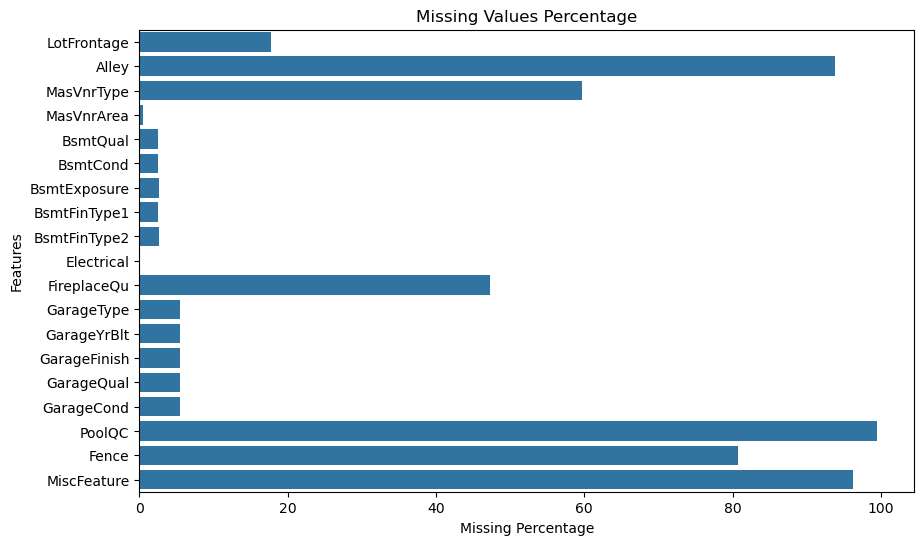

In [13]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=missing_df.reset_index(),
    x="Missing Percentage",
    y="index"
)

plt.xlabel("Missing Percentage")
plt.ylabel("Features")
plt.title("Missing Values Percentage")
plt.show()

## Observation

- The dataset contains **19 columns with missing values**, comprising a total of **7,829 missing entries**.
- Features such as **PoolQC**, **MiscFeature**, **Alley**, and **Fence** have a high percentage of missing values.
- Several garage and basement-related features contain a moderate number of missing values.
- Some features have only a few missing values (e.g., **Electrical** and **MasVnrArea**), which can be handled separately during preprocessing.
- Missing values may represent either unavailable information or the absence of a property feature rather than true missing data.
- Appropriate missing value handling strategies will be determined after further exploratory data analysis.

## Duplicate Values

In [14]:
df.duplicated().sum()

0

## Observation

- No duplicate records were found in the dataset.
- Therefore, no duplicate removal is required during the data preprocessing stage.

# Exploratory Data Analysis (EDA)

## Target Variable Analysis

In [15]:
pd.DataFrame(df["SalePrice"].describe()).T

,count,mean,std,min,25%,50%,75%,max
SalePrice,1460.0,180921.19589,79442.502883,34900.0,129975.0,163000.0,214000.0,755000.0


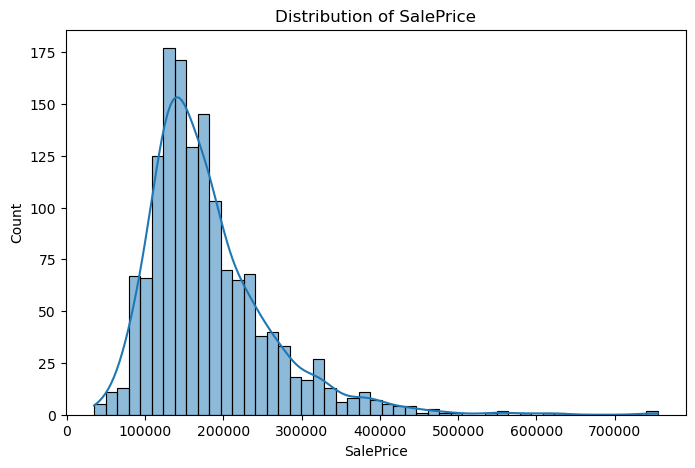

In [16]:
plt.figure(figsize=(8,5))

sns.histplot(df["SalePrice"], kde=True)

plt.title("Distribution of SalePrice")

plt.show()

## Observation

- The target variable, **SalePrice**, ranges from **34,900** to **755,000**, indicating a wide variation in house prices.
- The average house price is approximately **180,921**, while the median price is **163,000**.
- Since the **mean is greater than the median**, the distribution is positively (right) skewed.
- The histogram shows that most houses are sold between **100,000 and 250,000**, with fewer houses in the higher price range.
- A small number of high-priced houses create a long right tail, suggesting the presence of potential outliers.
- Due to the positive skewness, a **log transformation of `SalePrice`** may be considered later to improve the performance of regression models that assume a normally distributed target.

## Skewness of Target Variable

In [17]:
df['SalePrice'].skew()

1.8828757597682129

In [18]:
print(f"SalePrice Skewness : {df['SalePrice'].skew():.4f}")

SalePrice Skewness : 1.8829


### Observation

- The `SalePrice` variable has a skewness of **1.8829**, indicating a strong positive (right) skew.
- Most houses are concentrated in the lower-to-middle price range, while a smaller number of houses have substantially higher prices.
- The target distribution is therefore not approximately symmetric.
- This skewness will be considered during preprocessing, and we will later evaluate whether a transformation of the target improves regression performance.

## Target Variable  Outliers

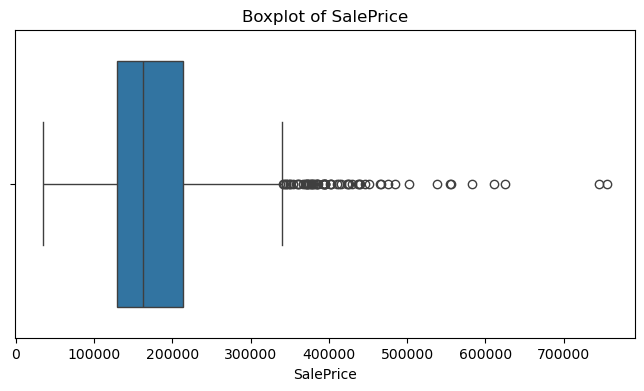

In [19]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["SalePrice"])

plt.title("Boxplot of SalePrice")
plt.xlabel("SalePrice")

plt.show()

### Observation

- The boxplot shows several potential outliers on the upper side of `SalePrice`.
- The presence of numerous high-priced observations explains the strong positive skewness observed earlier.
- These extreme values may represent genuine high-value properties rather than erroneous data.
- Therefore, the observations will not be removed solely based on the boxplot; their influence will be considered during modeling and further analysis.

## Numerical Feature Analysis

In [20]:
num_features = df.select_dtypes(include = np.number).columns.tolist()

num_features.remove("Id")
num_features.remove("SalePrice")

print(f"Number of Numerical Features : {len(num_features)}")

Number of Numerical Features : 36


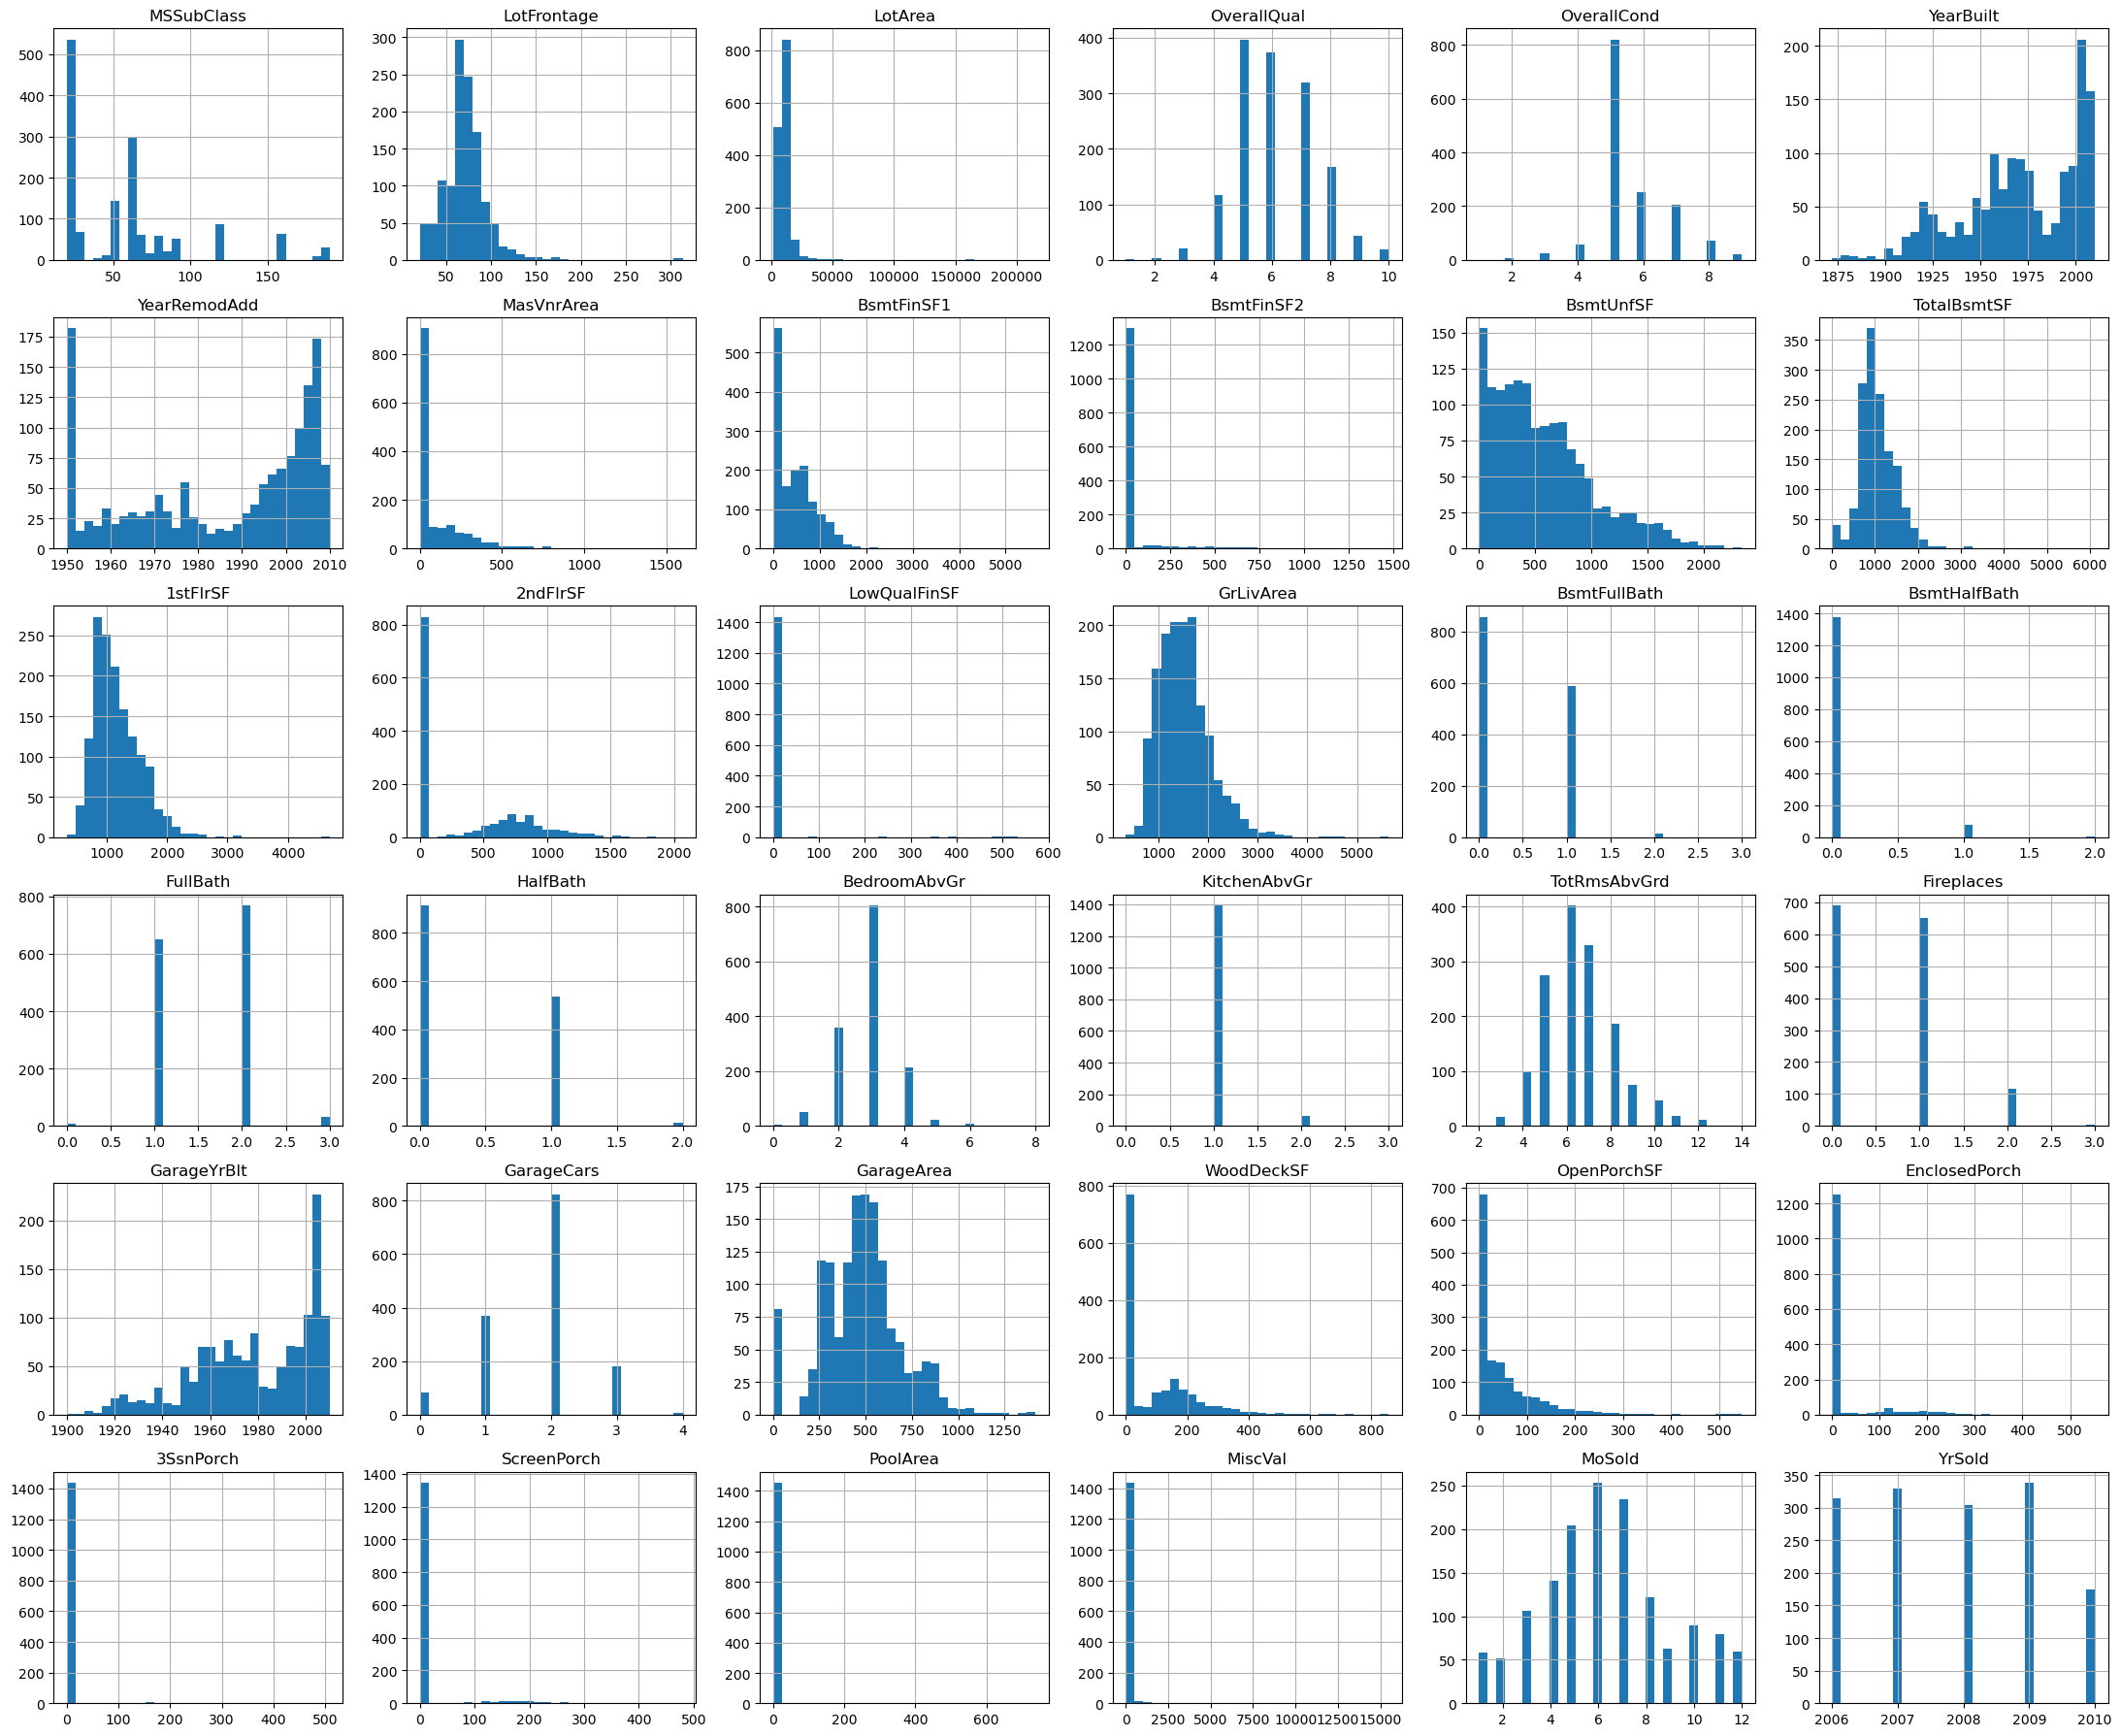

In [21]:
df[num_features].hist(figsize=(22, 18), bins=30)

plt.tight_layout()
plt.show()

### Observation

- The dataset contains **36 numerical features** with substantially different distributions.
- Several features, including `LotFrontage`, `LotArea`, `MasVnrArea`, `BsmtFinSF1`, `BsmtFinSF2`, `1stFlrSF`, `GrLivArea`, `WoodDeckSF`, and `OpenPorchSF`, show noticeable right-skewness.
- Some variables such as `OverallQual`, `OverallCond`, `BsmtFullBath`, `FullBath`, `HalfBath`, `GarageCars`, and `MoSold` are discrete or ordinal in nature rather than continuously distributed.
- Several features contain a large concentration of zero values, particularly variables related to basements, porches, pools, and other property amenities. These zeros may represent the absence of the corresponding feature.
- The numerical features have very different scales and ranges, which will be considered during preprocessing and model development.
- Some variables show potential extreme values that will require further investigation rather than being removed automatically.

## Relationship with SalePrice

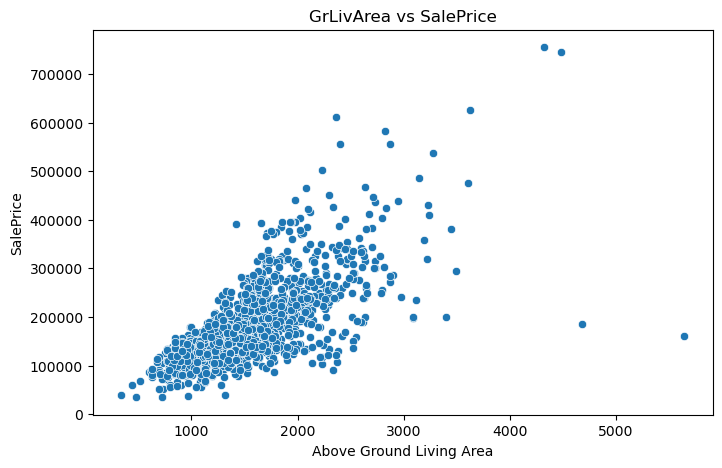

In [22]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("GrLivArea vs SalePrice")
plt.xlabel("Above Ground Living Area")
plt.ylabel("SalePrice")

plt.show()

### Observation

- `GrLivArea` shows a clear positive relationship with `SalePrice`, indicating that houses with larger above-ground living areas generally tend to have higher sale prices.
- The relationship is not perfectly linear, as the variation in price increases for larger living areas.
- A few houses with very large `GrLivArea` have unusually low sale prices compared with the overall trend and may represent potential outliers.
- Overall, `GrLivArea` appears to be an important predictor of house prices and will be considered during feature analysis and model development.

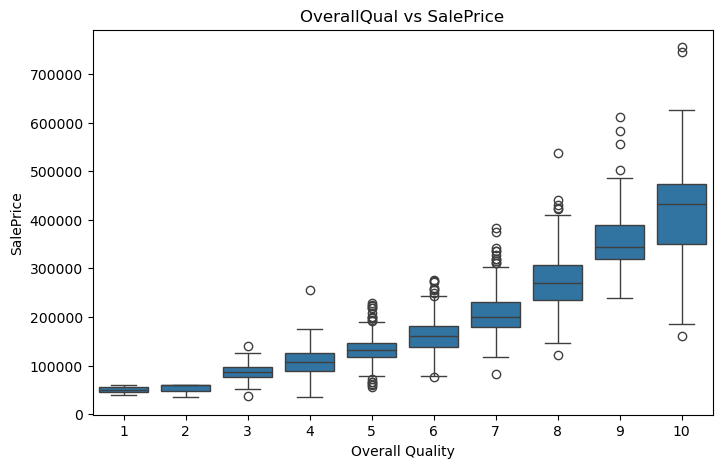

In [23]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="OverallQual",
    y="SalePrice"
)

plt.title("OverallQual vs SalePrice")
plt.xlabel("Overall Quality")
plt.ylabel("SalePrice")

plt.show()

### Observation

- `OverallQual` shows a strong positive relationship with `SalePrice`.
- As the overall quality rating increases from 1 to 10, the median sale price generally increases substantially.
- Higher-quality houses also show greater variation in sale prices, particularly for ratings 8–10.
- Several potential outliers are visible across the quality categories, especially among higher-quality properties.
- Overall, `OverallQual` appears to be one of the important features associated with house prices and will be considered for further analysis and model development.

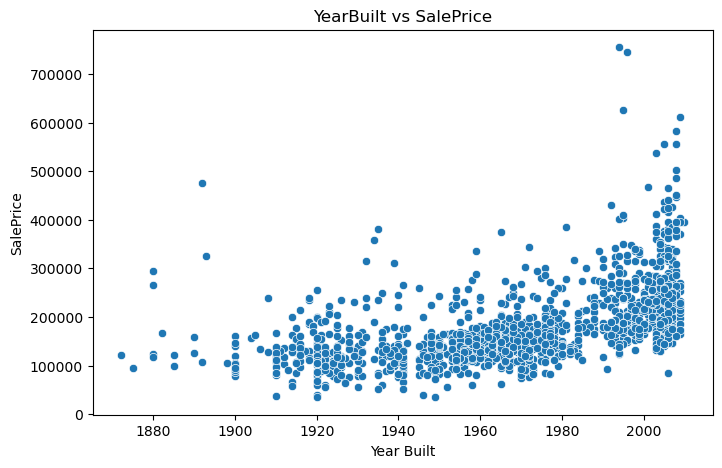

In [24]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="YearBuilt",
    y="SalePrice"
)

plt.title("YearBuilt vs SalePrice")
plt.xlabel("Year Built")
plt.ylabel("SalePrice")

plt.show()

### Observation

- `YearBuilt` shows a generally positive relationship with `SalePrice`, indicating that newer houses tend to have higher selling prices.
- Houses built in more recent years are more concentrated in the higher price ranges.
- However, substantial variation in `SalePrice` exists for houses built in the same period, suggesting that construction year alone does not determine house price.
- A few older and newer properties have unusually high sale prices, indicating potential outliers.
- Overall, `YearBuilt` appears to be a relevant feature, although its relationship with price is influenced by other property characteristics.

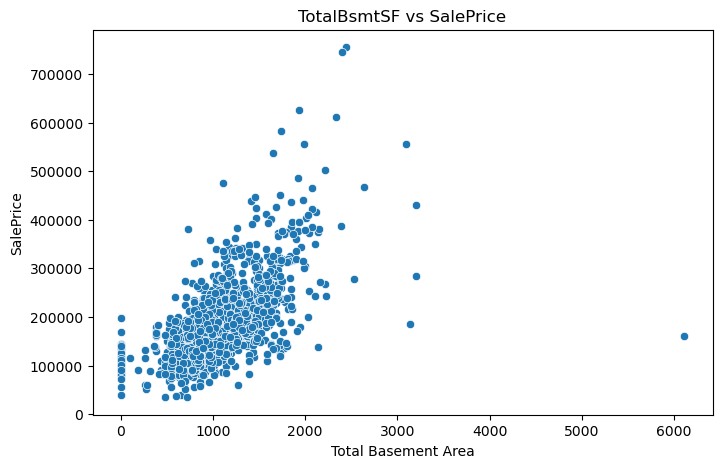

In [25]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="TotalBsmtSF",
    y="SalePrice"
)

plt.title("TotalBsmtSF vs SalePrice")
plt.xlabel("Total Basement Area")
plt.ylabel("SalePrice")

plt.show()

### Observation

- `TotalBsmtSF` shows a clear positive relationship with `SalePrice`, indicating that houses with larger total basement areas generally tend to have higher sale prices.
- A large concentration of properties has basement areas between approximately 500 and 2,000 square feet.
- Houses with no basement (`TotalBsmtSF = 0`) generally have lower sale prices compared with houses having basement space.
- The relationship becomes more variable at larger basement sizes, indicating that other factors also influence house prices.
- A few properties with unusually large basement areas and extreme sale prices can be considered potential outliers and will be investigated further.
- Overall, `TotalBsmtSF` appears to be an important numerical feature for predicting `SalePrice`.

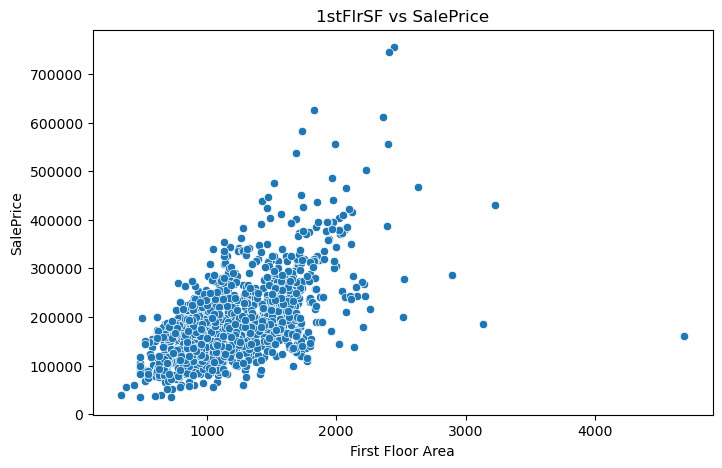

In [26]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="1stFlrSF",
    y="SalePrice"
)

plt.title("1stFlrSF vs SalePrice")
plt.xlabel("First Floor Area")
plt.ylabel("SalePrice")

plt.show()

### Observation

- `1stFlrSF` shows a clear positive relationship with `SalePrice`, indicating that houses with larger first-floor areas generally tend to have higher sale prices.
- Most properties have a first-floor area between approximately 500 and 2,000 square feet.
- The spread in sale prices increases as the first-floor area becomes larger, suggesting that other features also influence the final price.
- A few properties with extremely large first-floor areas have relatively low sale prices and may represent potential outliers.
- Overall, `1stFlrSF` appears to be an important numerical feature for predicting `SalePrice`.

## Correlation Analysis

In [27]:
corr_with_target = (
    df.select_dtypes(include=np.number)
      .corr()["SalePrice"]
      .sort_values(ascending=False)
)

corr_with_target

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

In [28]:
corr_with_target[corr_with_target>0.8]

SalePrice    1.0
Name: SalePrice, dtype: float64

### Observation

- `OverallQual` has the strongest positive correlation with `SalePrice` (**0.7900**), indicating that overall house quality has a strong linear relationship with selling price.
- `GrLivArea` is the second strongest positively correlated feature (**0.7086**), showing that larger above-ground living areas are generally associated with higher prices.
- Other strongly correlated features include `GarageCars` (0.6404), `GarageArea` (0.6234), `TotalBsmtSF` (0.6136), and `1stFlrSF` (0.6065).
- Features such as `YearBuilt` (0.5229) and `YearRemodAdd` (0.5071) also show moderate positive relationships with `SalePrice`.
- Some features, including `KitchenAbvGr` (-0.1359), `EnclosedPorch` (-0.1286), and `MSSubClass` (-0.0843), show weak negative correlations with the target.
- Correlation measures only linear relationships and does not capture all possible relationships between features and house prices.

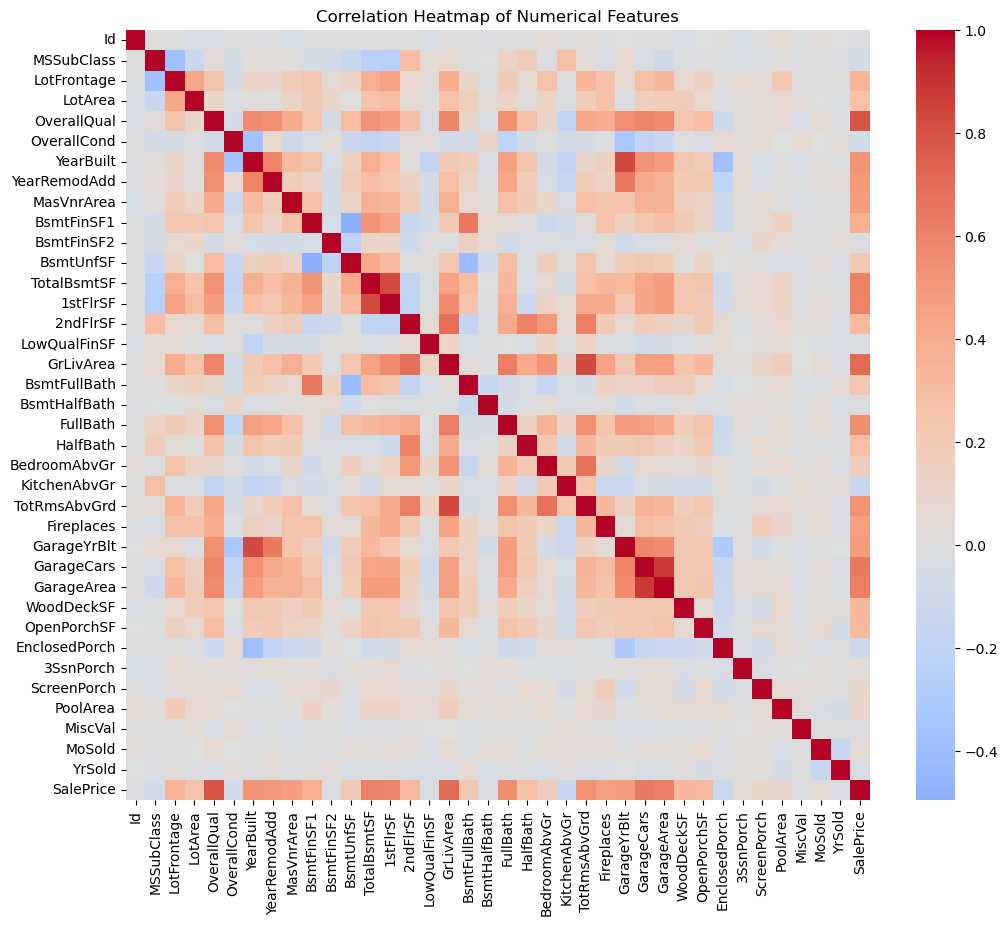

In [29]:
plt.figure(figsize=(12, 10))

corr_matrix = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

### Observation

- The heatmap shows that `OverallQual`, `GrLivArea`, `GarageCars`, `GarageArea`, `TotalBsmtSF`, and `1stFlrSF` have relatively strong positive relationships with `SalePrice`.
- Several numerical features are also correlated with each other. For example, `GarageCars` and `GarageArea`, and `1stFlrSF` and `TotalBsmtSF`, show noticeable positive relationships.
- This indicates that some features contain overlapping information, which may be relevant when developing regression models.
- `Id` shows very little relationship with `SalePrice` and does not appear to provide meaningful predictive information.
- The heatmap also shows that many other numerical features have weak relationships with the target.
- Correlation alone will not be used to remove features because it captures only linear relationships and some models can capture nonlinear relationships.

## Categorical Feature Analysis

### Checking Influence of Categorical Feature on Target

In [30]:
df["Neighborhood"].value_counts()

Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
StoneBr     25
SWISU       25
MeadowV     17
Blmngtn     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64

In [31]:
df["Neighborhood"].isnull().sum()

0

In [32]:
neighborhood_price = (
    df.groupby("Neighborhood")["SalePrice"]
      .median()
      .sort_values(ascending=False)
)

neighborhood_price

Neighborhood
NridgHt    315000.0
NoRidge    301500.0
StoneBr    278000.0
Timber     228475.0
Somerst    225500.0
Veenker    218000.0
Crawfor    200624.0
ClearCr    200250.0
CollgCr    197200.0
Blmngtn    191000.0
NWAmes     182900.0
Gilbert    181000.0
SawyerW    179900.0
Mitchel    153500.0
NPkVill    146000.0
NAmes      140000.0
SWISU      139500.0
Blueste    137500.0
Sawyer     135000.0
BrkSide    124300.0
Edwards    121750.0
OldTown    119000.0
BrDale     106000.0
IDOTRR     103000.0
MeadowV     88000.0
Name: SalePrice, dtype: float64

### Observation

- Median `SalePrice` varies substantially across neighborhoods, indicating that location is an important factor in house prices.
- `NridgHt` has the highest median sale price at approximately **315,000**, followed by `NoRidge` (**301,500**) and `StoneBr` (**278,000**).
- `MeadowV` has the lowest median sale price at approximately **88,000**, followed by `IDOTRR` (**103,000**) and `BrDale` (**106,000**).
- The large difference between the highest- and lowest-priced neighborhoods suggests that neighborhood characteristics may have a significant influence on house prices.
- This feature is therefore likely to be important for both **model prediction** and later **business recommendations**.

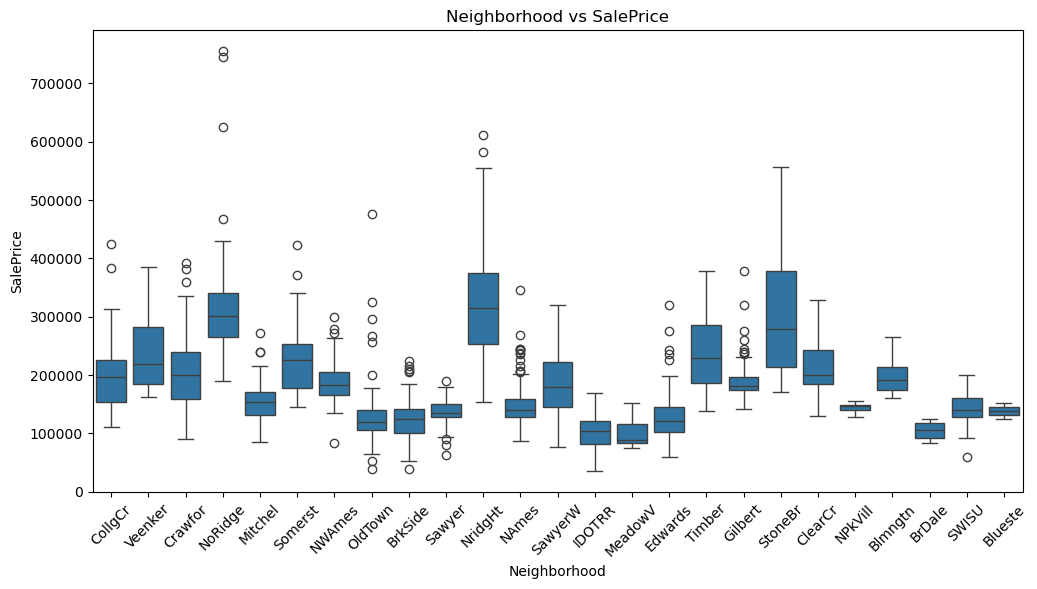

In [33]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Neighborhood",
    y="SalePrice"
)

plt.xticks(rotation=45)
plt.title("Neighborhood vs SalePrice")
plt.xlabel("Neighborhood")
plt.ylabel("SalePrice")

plt.show()

### Observation

- Sale prices vary substantially across neighborhoods, confirming that location is an important factor in house pricing.
- `NridgHt`, `NoRidge`, and `StoneBr` generally have higher price distributions, while `MeadowV`, `IDOTRR`, and `BrDale` tend to have lower price distributions.
- The spread of prices also differs considerably across neighborhoods, indicating varying levels of price variability.
- Several neighborhoods contain high-price outliers, particularly `NridgHt` and `NoRidge`.
- Overall, `Neighborhood` is an important categorical feature and is likely to contribute significantly to house price prediction and customer recommendations.

In [34]:
df["HouseStyle"].value_counts()

HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64

In [35]:
df["HouseStyle"].isnull().sum()

0

In [36]:
house_style_price = (
    df.groupby("HouseStyle")["SalePrice"]
    .median()
    .sort_values(ascending=False)
)

house_style_price

HouseStyle
2.5Fin    194000.0
2Story    190000.0
SLvl      164500.0
1Story    154750.0
SFoyer    135960.0
2.5Unf    133900.0
1.5Fin    132000.0
1.5Unf    111250.0
Name: SalePrice, dtype: float64

### Observation

- Median `SalePrice` varies across different house styles, indicating that house style may influence property prices.
- `2.5Fin` has the highest median sale price (**194,000**), followed by `2Story` (**190,000**) and `SLvl` (**164,500**).
- `1.5Unf` has the lowest median sale price (**111,250**), followed by `1.5Fin` (**132,000**).
- However, categories such as `2.5Fin`, `2.5Unf`, and `1.5Unf` contain relatively few observations, so their median prices should be interpreted cautiously.
- Overall, `HouseStyle` appears to have some relationship with `SalePrice`, but its effect may also depend on other property characteristics.

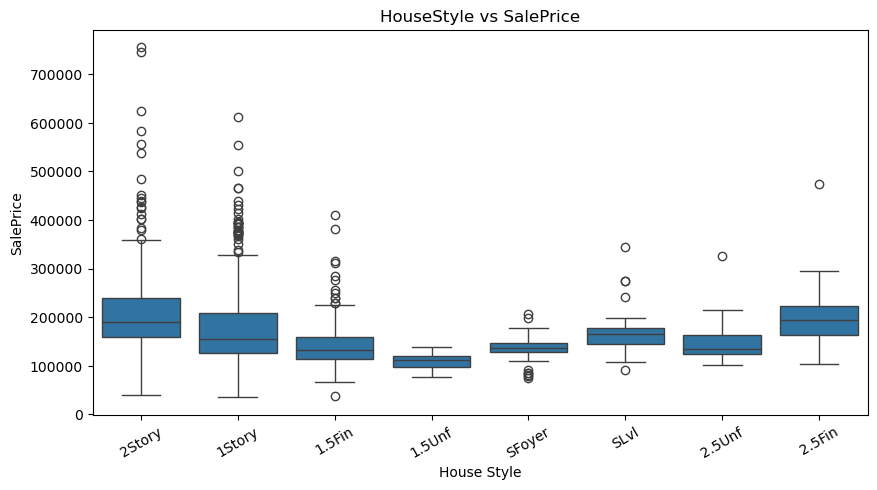

In [37]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="HouseStyle",
    y="SalePrice"
)

plt.xticks(rotation=30)
plt.title("HouseStyle vs SalePrice")
plt.xlabel("House Style")
plt.ylabel("SalePrice")

plt.show()

### Observation

- `SalePrice` distributions differ across house styles, indicating that house style has some influence on house prices.
- `2Story` and `2.5Fin` properties generally show higher median prices compared with several other house styles.
- `1.5Unf` and `1.5Fin` properties tend to have lower median prices.
- `2Story` and `1Story` contain many high-price outliers, showing substantial variation within these categories.
- Some house styles have relatively few observations, so their price distributions should be interpreted cautiously.
- Overall, `HouseStyle` provides useful categorical information, but its effect on price is likely influenced by other characteristics such as quality, living area, and location.

In [38]:
df["ExterQual"].value_counts()

ExterQual
TA    906
Gd    488
Ex     52
Fa     14
Name: count, dtype: int64

In [39]:
df["ExterQual"].isnull().sum()

0

In [40]:
exter_qual_price = (
    df.groupby("ExterQual")["SalePrice"]
    .median()
    .sort_values(ascending=False)
)

exter_qual_price

ExterQual
Ex    364606.5
Gd    220000.0
TA    139450.0
Fa     82250.0
Name: SalePrice, dtype: float64

### Observation

- Median `SalePrice` varies substantially across exterior quality categories.
- Houses with **Excellent (`Ex`)** exterior quality have the highest median sale price of approximately **364,607**.
- Houses with **Good (`Gd`)** exterior quality have a median sale price of **220,000**.
- Median prices decrease further for **Typical/Average (`TA`)** at **139,450** and **Fair (`Fa`)** at **82,250**.
- The consistent increase in median price with better exterior quality suggests that `ExterQual` is an important categorical feature associated with house prices.

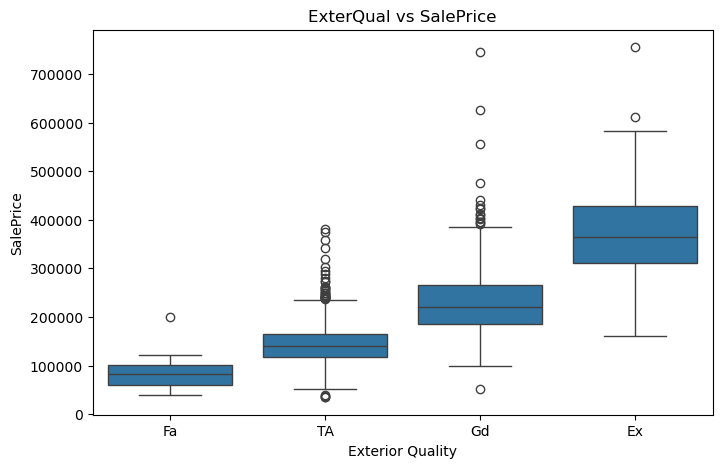

In [41]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="ExterQual",
    y="SalePrice",
    order=["Fa", "TA", "Gd", "Ex"]
)

plt.title("ExterQual vs SalePrice")
plt.xlabel("Exterior Quality")
plt.ylabel("SalePrice")

plt.show()

### Observation

- `ExterQual` shows a strong relationship with `SalePrice`, with house prices generally increasing as exterior quality improves.
- Properties with **Excellent (`Ex`)** exterior quality have the highest price distribution, while **Fair (`Fa`)** quality properties have the lowest.
- The median sale price increases consistently from `Fa` → `TA` → `Gd` → `Ex`.
- Higher-quality categories also contain several high-price outliers, indicating that other property characteristics contribute to the final price.
- Overall, `ExterQual` appears to be an important categorical feature for predicting `SalePrice`.

## Handling Missing Values

### Missing-Value  PoolQC

In [42]:
df.groupby(df["PoolQC"].isna())["PoolArea"].describe()

,count,mean,std,min,25%,50%,75%,max
PoolQC,,,,,,,,
False,7.0,575.428571,89.840335,480.0,515.5,555.0,612.0,738.0
True,1453.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0


### Observation

- `PoolQC` contains 1,453 missing values; however, these missing values correspond to properties with `PoolArea = 0`.
- This indicates that a missing value in `PoolQC` represents the **absence of a swimming pool**, rather than missing information.
- Therefore, during preprocessing, the missing `PoolQC` values should be treated as a separate category such as **"None"** rather than being imputed using the mode.
- This approach preserves the information that the property does not have a pool.

### Missing-Value Garatype

In [43]:
df.groupby(df["GarageType"].isna())["GarageArea"].describe()

,count,mean,std,min,25%,50%,75%,max
GarageType,,,,,,,,
False,1379.0,500.762146,185.68052,160.0,380.0,484.0,580.0,1418.0
True,81.0,0.000000,0.00000,0.0,0.0,0.0,0.0,0.0


### Observation

- `GarageType` contains 81 missing values, and all corresponding properties have `GarageArea = 0`.
- This indicates that the missing values represent the **absence of a garage** rather than missing information.
- Therefore, missing `GarageType` values should be treated as a separate category such as **"None"** during preprocessing.
- Related garage categorical features should be investigated similarly to preserve the information that the property has no garage.

### Missing-Value BsmtFinType1	

In [44]:
df.groupby(df["BsmtFinType1"].isna())["TotalBsmtSF"].describe()

,count,mean,std,min,25%,50%,75%,max
BsmtFinType1,,,,,,,,
False,1423.0,1084.924104,409.413709,105.0,810.5,1004.0,1309.5,6110.0
True,37.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0


### Observation

- `BsmtFinType1` contains 37 missing values, and all corresponding properties have `TotalBsmtSF = 0`.
- This confirms that the missing values represent the **absence of a basement**, rather than unknown information.
- Therefore, missing values in basement-related categorical features should be treated as **"None"** during preprocessing.
- This approach preserves the information that the property does not have a basement.

### Missing-Value Alley

In [45]:
df.groupby(df["Alley"].isna())["SalePrice"].describe()

,count,mean,std,min,25%,50%,75%,max
Alley,,,,,,,,
False,91.0,142845.912088,42867.137343,40000.0,114752.0,140000.0,172200.0,265979.0
True,1369.0,183452.131483,80667.145180,34900.0,130500.0,165000.0,217500.0,755000.0


### Observation

- `Alley` contains 1,369 missing values out of 1,460 observations.
- Since `Alley` represents the type of alley access, the high number of missing values is likely associated with properties that do not have alley access.
- Therefore, these missing values can be treated as a separate category such as **"None"** during preprocessing rather than using statistical imputation.

### Missing-Value Fence

In [46]:
df["Fence"].value_counts(dropna=False)

Fence
NaN      1179
MnPrv     157
GdPrv      59
GdWo       54
MnWw       11
Name: count, dtype: int64

### Observation

- `Fence` contains 1,179 missing values out of 1,460 observations.
- The observed categories represent different types of fencing, while the majority of properties have no recorded fence type.
- The missing values can therefore be treated as a separate **"None"** category during preprocessing to represent the absence of fencing.
- Statistical imputation would not be appropriate because the missing value carries meaningful information about the property.

### Missing-Value MiscFeature

In [47]:
df["MiscFeature"].value_counts(dropna=False)

MiscFeature
NaN     1406
Shed      49
Gar2       2
Othr       2
TenC       1
Name: count, dtype: int64

### Observation

- `MiscFeature` contains 1,406 missing values, making it one of the most sparsely populated categorical features.
- The observed categories represent optional miscellaneous features such as sheds and other facilities.
- The large number of missing values indicates that most properties do not have a recorded miscellaneous feature.
- Therefore, missing values can be treated as a separate **"None"** category during preprocessing rather than using statistical imputation.

### Missing-Value MasVnrType

In [48]:
df["MasVnrType"].value_counts(dropna=False)

MasVnrType
NaN        872
BrkFace    445
Stone      128
BrkCmn      15
Name: count, dtype: int64

In [49]:
df.groupby(df["MasVnrType"].isna())["MasVnrArea"].describe()

,count,mean,std,min,25%,50%,75%,max
MasVnrType,,,,,,,,
False,588.0,254.430272,205.620539,0.0,112.75,202.5,329.25,1600.0
True,864.0,1.094907,18.569659,0.0,0.00,0.0,0.00,344.0


In [ ]:
df.loc[
    df["MasVnrType"].isna() & (df["MasVnrArea"] > 0),
    ["MasVnrType", "MasVnrArea", "SalePrice"]
]

### Observation

- Most properties with missing `MasVnrType` have `MasVnrArea = 0`, suggesting that the missing category often represents the absence of masonry veneer.
- However, 5 observations have missing `MasVnrType` but positive `MasVnrArea`.
- Therefore, the missing values cannot be assumed to represent "None" in every case.
- These exceptional records require further consideration during preprocessing before assigning a category or imputing the missing values.

### Missing-Value MasVnrArea

In [51]:
df["MasVnrArea"].isnull().sum()

8

In [ ]:
df.loc[
    df["MasVnrArea"].isna(),
    ["MasVnrType", "MasVnrArea", "SalePrice"]
]

### Observation

- All 8 observations with missing `MasVnrArea` also have missing `MasVnrType`.
- Most properties with missing `MasVnrType` have zero masonry veneer area, although a small number of exceptions have positive `MasVnrArea`.
- During preprocessing, missing `MasVnrType` can be treated as **"None"**, while missing `MasVnrArea` can be treated as **0**, representing the absence of recorded masonry veneer area.
- The few inconsistent cases with positive `MasVnrArea` and missing `MasVnrType` should be retained rather than removed.

### Missing-Value Electrical

In [53]:
df["Electrical"].value_counts(dropna=False)

Electrical
SBrkr    1334
FuseA      94
FuseF      27
FuseP       3
Mix         1
NaN         1
Name: count, dtype: int64

### Observation

- `Electrical` contains only **one missing value**, making the missingness negligible compared with the total dataset size.
- `SBrkr` is the dominant category, with **1,334 observations**.
- Since `Electrical` does not represent the absence of an electrical system, the missing value should not be treated as `"None"`.
- During preprocessing, the single missing value can be imputed using the **mode (`SBrkr`)**.

## Grouping Missing Values

In [54]:
garage_cols = [
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond"
]

df[garage_cols].isnull().sum()

GarageType      81
GarageFinish    81
GarageQual      81
GarageCond      81
dtype: int64

In [ ]:
df.loc[
    df["GarageType"].isna(),
    garage_cols + ["GarageArea", "GarageCars"]
]

In [ ]:
df.loc[
    df["GarageYrBlt"].isna(),
    ["GarageType", "GarageYrBlt", "GarageArea", "GarageCars"]
]

### Garage Missing-Value Analysis — Observation

- `GarageType`, `GarageFinish`, `GarageQual`, and `GarageCond` each contain 81 missing values.
- The missing values occur for the same properties, and these properties have `GarageArea = 0` and `GarageCars = 0`.
- Therefore, the missing values in these garage-related categorical features represent the **absence of a garage**, rather than missing information.
- During preprocessing, these missing values can be treated as a separate **"None"** category.

In [57]:
basement_cols = [
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2"
]

df[basement_cols].isnull().sum()

BsmtQual        37
BsmtCond        37
BsmtExposure    38
BsmtFinType1    37
BsmtFinType2    38
dtype: int64

In [ ]:
df.loc[
    df[basement_cols].isnull().any(axis=1),
    basement_cols + ["TotalBsmtSF", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF"]
]

In [ ]:
df.loc[
    df[basement_cols].isnull().any(axis=1) & (df["TotalBsmtSF"] > 0),
    basement_cols + ["TotalBsmtSF", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF"]
]

### Basement Missing-Value Analysis — Final Observation

- Most missing basement categorical values occur in properties with `TotalBsmtSF = 0`, indicating that these properties do not have a basement.
- Two exceptions were identified:
  - Row 332 has a basement (`TotalBsmtSF = 3206`) but `BsmtFinType2` is missing.
  - Row 948 has a basement (`TotalBsmtSF = 936`) but `BsmtExposure` is missing.
- Therefore, missing basement values should be handled based on the context of each property rather than assigning `"None"` to every missing value.
- For properties with no basement, `"None"` can represent the absence of the feature.
- The isolated missing attributes in existing basements require separate categorical imputation during preprocessing.

In [60]:
df.groupby(df["LotFrontage"].isna())["LotArea"].describe()

,count,mean,std,min,25%,50%,75%,max
LotFrontage,,,,,,,,
False,1201.0,9951.698585,7924.353975,1300.0,7420.0,9262.0,11249.0,215245.0
True,259.0,13137.370656,16215.264451,1974.0,8065.5,10624.0,13018.5,164660.0


### LotFrontage Missing-Value Analysis — Observation

- `LotFrontage` contains 259 missing values.
- Properties with missing `LotFrontage` still have valid `LotArea` values, indicating that the missing values do not represent the absence of a lot.
- Therefore, the missing values should not be replaced with zero.
- Since `LotFrontage` is a numerical feature, an appropriate statistical or model-based imputation strategy will be considered during preprocessing.

In [61]:
df.groupby(
    df["FireplaceQu"].isna()
)["Fireplaces"].describe()

,count,mean,std,min,25%,50%,75%,max
FireplaceQu,,,,,,,,
False,770.0,1.162338,0.386219,1.0,1.0,1.0,1.0,3.0
True,690.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0


### FireplaceQu — Missing-Value Treatment

- `FireplaceQu` contains 690 missing values in the training data.
- All properties with missing `FireplaceQu` have `Fireplaces = 0`.
- Therefore, the missing values represent the absence of a fireplace rather than unknown quality.
- Missing `FireplaceQu` values will be treated as **"None"** during preprocessing.

### Overall EDA Observations

- `SalePrice` is strongly right-skewed, with a skewness of **1.8829**, and contains several high-price observations that may influence regression models.
- `OverallQual` and `GrLivArea` show the strongest relationships with `SalePrice`, while `GarageCars`, `GarageArea`, `TotalBsmtSF`, and `1stFlrSF` also show strong positive relationships.
- `Neighborhood` shows substantial differences in median house prices, highlighting the importance of location in determining property value.
- `ExterQual` shows a clear increasing trend in house prices as exterior quality improves.
- `HouseStyle` shows differences in price distributions, although some categories contain relatively few observations.
- Several numerical features are right-skewed and some contain potential outliers that will require consideration during preprocessing.
- Several numerical variables are correlated with one another, indicating that some features contain overlapping information.
- Missing-value analysis revealed that many categorical missing values represent the **absence of a property feature**, such as no pool, garage, basement, fence, or miscellaneous feature.
- `Electrical` has only one missing observation and can be handled separately using an appropriate categorical imputation strategy.
- These findings will guide the feature engineering, missing-value treatment, transformation, and model development stages.

## Data Preprocessing

## Separate Features and Target

In [62]:
X = df.drop(columns = ["SalePrice"])
y = df["SalePrice"]

print("X shape", X.shape)
print("y shape",y.shape)

X shape (1460, 80)
y shape (1460,)


## Train-Test Split

In [63]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (1168, 80)
X_test : (292, 80)
y_train: (1168,)
y_test : (292,)


In [64]:
X_train = X_train.drop("Id", axis=1)
X_test = X_test.drop("Id", axis=1)

In [65]:
missing_train = X_train.isnull().sum()
missing_train = missing_train[missing_train > 0].sort_values(ascending=False)

missing_train

PoolQC          1162
MiscFeature     1122
Alley           1094
Fence            935
MasVnrType       683
FireplaceQu      547
LotFrontage      217
GarageType        64
GarageYrBlt       64
GarageFinish      64
GarageQual        64
GarageCond        64
BsmtFinType1      28
BsmtFinType2      28
BsmtExposure      28
BsmtCond          28
BsmtQual          28
MasVnrArea         6
Electrical         1
dtype: int64

## Imputing Missing Values

In [66]:
none_cols = [
    "PoolQC",
    "MiscFeature",
    "Alley",
    "Fence",
    "FireplaceQu"
]

X_train[none_cols] = X_train[none_cols].fillna("None")

In [67]:
X_train[none_cols].isnull().sum()

PoolQC         0
MiscFeature    0
Alley          0
Fence          0
FireplaceQu    0
dtype: int64

### Observation

- The columns `PoolQC`, `MiscFeature`, `Alley`, `Fence`, and `FireplaceQu` contain missing values that indicate the **absence of the respective feature**.
- These missing values were replaced with `"None"` instead of removing the observations or applying statistical imputation.
- After imputation, all five columns contain **0 missing values**.
- This confirms that the categorical missing-value treatment was completed successfully.

In [68]:
garage_cat_cols =[
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond"
]

X_train[garage_cat_cols] = X_train[garage_cat_cols].fillna("None")

In [69]:
X_train[garage_cat_cols].isnull().sum()

GarageType      0
GarageFinish    0
GarageQual      0
GarageCond      0
dtype: int64

In [70]:
X_train["GarageYrBlt"] = X_train["GarageYrBlt"].fillna(0)

In [71]:
X_train["GarageYrBlt"].isnull().sum()

0

### Observation

- The categorical garage-related columns (`GarageType`, `GarageFinish`, `GarageQual`, and `GarageCond`) had missing values representing the **absence of a garage-related feature**.
- These missing values were replaced with `"None"` to explicitly represent the absence of the feature.
- The `GarageYrBlt` column had missing values, which were replaced with `0` to represent the **absence of a garage year value**.
- After imputation, all five garage-related columns contain **0 missing values**.
- This confirms that the missing-value treatment for garage-related features was completed successfully.

In [72]:
basement_cat_cols = [
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2"
]

X_train[basement_cat_cols] = X_train[basement_cat_cols].fillna("None")

In [73]:
X_train[basement_cat_cols].isnull().sum()

BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
dtype: int64

### Observation

- The basement-related categorical columns (`BsmtQual`, `BsmtCond`, `BsmtExposure`, `BsmtFinType1`, and `BsmtFinType2`) had missing values representing the **absence of a basement feature**.
- These missing values were replaced with `"None"` to explicitly represent the absence of the respective basement feature.
- After imputation, all five columns contain **0 missing values**.
- This confirms that the missing-value treatment for basement-related categorical features was completed successfully.

In [74]:
X_train["MasVnrType"] = X_train["MasVnrType"].fillna("None")
X_train["MasVnrArea"] = X_train["MasVnrArea"].fillna(0)

In [75]:
X_train[["MasVnrType", "MasVnrArea"]].isnull().sum()

MasVnrType    0
MasVnrArea    0
dtype: int64

### Observation

- The `MasVnrType` column had missing values, which were replaced with `"None"` to represent the **absence of a masonry veneer**.
- The `MasVnrArea` column had missing values, which were replaced with `0` to represent **no masonry veneer area**.
- After imputation, both columns contain **0 missing values**.
- This confirms that the missing-value treatment for masonry veneer features was completed successfully.

In [76]:
electrical_mode = X_train["Electrical"].mode()[0]

X_train["Electrical"] = X_train["Electrical"].fillna(electrical_mode)

print("Imputed value:", electrical_mode)
print("Missing values:", X_train["Electrical"].isnull().sum())

Imputed value: SBrkr
Missing values: 0


### Observation

- The `Electrical` column contained missing values, so **mode imputation** was used to fill them.
- The most frequent category (mode) was **`SBkr`**, which was used as the imputed value.
- After imputation, the number of missing values decreased to **0**.
- This confirms that the missing values in the `Electrical` column were successfully handled using the most frequent category.

In [77]:
lot_frontage_median = X_train["LotFrontage"].median()

X_train["LotFrontage"] = X_train["LotFrontage"].fillna(lot_frontage_median)

print("Median used:", lot_frontage_median)
print("Missing values:", X_train["LotFrontage"].isnull().sum())

Median used: 70.0
Missing values: 0


### Observation

- The `LotFrontage` column contained missing values, so **median imputation** was used to handle them.
- The median value of `LotFrontage` was **70.0**, and this value was used to replace the missing observations.
- After imputation, the number of missing values decreased to **0**.
- Median imputation was used because `LotFrontage` is a numerical feature and the median is less sensitive to extreme values than the mean.

In [78]:
missing_train = X_train.isnull().sum()

missing_train[missing_train > 0]

Series([], dtype: int64)

In [79]:
print("Total missing values in X_train:", X_train.isnull().sum().sum())

Total missing values in X_train: 0


### Observation

- The total number of missing values in `X_train` is **0**.
- This confirms that all identified missing values have been successfully handled through the appropriate imputation techniques.
- Therefore, `X_train` is now **complete and contains no missing observations**, making it ready for further preprocessing and model building.

In [80]:
none_cols = [
    "PoolQC",
    "MiscFeature",
    "Alley",
    "Fence",
    "FireplaceQu"
]

X_test[none_cols] = X_test[none_cols].fillna("None")

In [81]:
X_test[none_cols].isnull().sum()

PoolQC         0
MiscFeature    0
Alley          0
Fence          0
FireplaceQu    0
dtype: int64

In [82]:
garage_cat_cols = [
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond"
]

X_test[garage_cat_cols] = X_test[garage_cat_cols].fillna("None")

In [83]:
X_test[garage_cat_cols].isnull().sum()

GarageType      0
GarageFinish    0
GarageQual      0
GarageCond      0
dtype: int64

In [84]:
X_test["GarageYrBlt"] = X_test["GarageYrBlt"].fillna(0)

print("Missing values:", X_test["GarageYrBlt"].isnull().sum())

Missing values: 0


In [85]:
basement_cat_cols = [
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2"
]

X_test[basement_cat_cols] = X_test[basement_cat_cols].fillna("None")

In [86]:
X_test[basement_cat_cols].isnull().sum()

BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
dtype: int64

In [87]:
X_test["MasVnrType"] = X_test["MasVnrType"].fillna("None")
X_test["MasVnrArea"] = X_test["MasVnrArea"].fillna(0)

In [88]:
print(
    X_test[["MasVnrType", "MasVnrArea"]]
    .isnull()
    .sum()
)

MasVnrType    0
MasVnrArea    0
dtype: int64


In [89]:
X_test["Electrical"] = X_test["Electrical"].fillna(electrical_mode)

In [90]:
lot_frontage_median = X_train["LotFrontage"].median()

X_test["LotFrontage"] = X_test["LotFrontage"].fillna(lot_frontage_median)

In [91]:
missing_test = X_test.isnull().sum()

print(missing_test[missing_test > 0])
print("Total missing values in X_test:", X_test.isnull().sum().sum())

Series([], dtype: int64)
Total missing values in X_test: 0


In [92]:
print(X_train.isna().sum().sum())
print(X_test.isna().sum().sum())

0
0


### Observation

- The same missing-value treatment applied to `X_train` was also applied to `X_test` for all identified features.
- The imputation methods were kept consistent between the training and test sets to ensure that both datasets have the same preprocessing structure.
- The missing-value check for `X_test` shows **0 missing values across all features**.
- This confirms that the missing-value treatment was completed successfully for both the training and test datasets.
- Therefore, both `X_train` and `X_test` are now **free of missing values and ready for further preprocessing and model building**.

In [93]:
print(X_train.shape)
print(X_test.shape)

(1168, 79)
(292, 79)


In [ ]:
X_train

## Encoding

In [95]:
categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
numerical_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Number of categorical features:", len(categorical_cols))
print("Number of numerical features:", len(numerical_cols))

print("\nCategorical features:")
print(categorical_cols)

Number of categorical features: 43
Number of numerical features: 36

Categorical features:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


### Observation

- The dataset contains 43 categorical and 37 numerical features after separating the target variable.
- The categorical features represent property characteristics such as neighborhood, quality, condition, house style, garage, basement, and exterior features.
- Since machine learning regression models require numerical inputs, the categorical features need to be encoded before model training.
- One-hot encoding will be considered for the categorical variables to convert their categories into numerical representations while avoiding an artificial ordinal relationship between categories.

In [96]:
categorical_cardinality = (
    X_train[categorical_cols]
    .nunique()
    .sort_values(ascending=False)
)

categorical_cardinality

Neighborhood     25
Exterior2nd      16
Exterior1st      15
SaleType          9
Condition1        9
Condition2        8
HouseStyle        8
BsmtFinType1      7
RoofMatl          7
BsmtFinType2      7
Functional        7
GarageType        7
Foundation        6
Heating           6
SaleCondition     6
RoofStyle         6
GarageQual        6
GarageCond        6
FireplaceQu       6
BsmtExposure      5
HeatingQC         5
Fence             5
MiscFeature       5
MSZoning          5
BsmtCond          5
BldgType          5
LotConfig         5
BsmtQual          5
ExterCond         5
Electrical        4
KitchenQual       4
MasVnrType        4
ExterQual         4
GarageFinish      4
PoolQC            4
LandContour       4
LotShape          4
PavedDrive        3
Alley             3
LandSlope         3
CentralAir        2
Street            2
Utilities         2
dtype: int64

## OneHotEncoding

In [97]:
from sklearn.preprocessing import OneHotEncoder

encoder_lr = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

X_train_encoded_lr = encoder_lr.fit_transform(
    X_train[categorical_cols]
)

X_test_encoded_lr = encoder_lr.transform(
    X_test[categorical_cols]
)

print("Encoded train:", X_train_encoded_lr.shape)
print("Encoded test :", X_test_encoded_lr.shape)

Encoded train: (1168, 221)
Encoded test : (292, 221)


In [98]:
X_train_final = np.hstack([
    X_train[numerical_cols].values,
    X_train_encoded_lr
])

X_test_final= np.hstack([
    X_test[numerical_cols].values,
    X_test_encoded_lr
])

print("X_train_final:", X_train_final.shape)
print("X_test_final :", X_test_final.shape)

X_train_final: (1168, 257)
X_test_final : (292, 257)


### Observation

- One-hot encoding was applied to the categorical features using `OneHotEncoder`.
- `drop="first"` was used to remove the first category from each categorical feature and avoid redundant dummy variables.
- `handle_unknown="ignore"` ensures that unseen categories in the test set do not cause errors during transformation.
- The categorical features were transformed into **221 encoded features** for both training and test sets.
- The numerical features were then combined with the encoded categorical features.
- The final training dataset contains **1,168 observations and 257 features**, while the final test dataset contains **292 observations and 257 features**.
- Both datasets have the same number of features, ensuring they are aligned and ready for model training and evaluation.

## Checking Skewness for Scaling

In [99]:
numerical_skewness = (
    X_train[numerical_cols]
    .skew()
    .sort_values(ascending=False)
)

numerical_skewness

MiscVal          22.053579
PoolArea         14.396098
LotArea          11.958088
3SsnPorch         9.833911
LowQualFinSF      9.199456
KitchenAbvGr      4.445055
BsmtFinSF2        4.217895
ScreenPorch       4.090393
BsmtHalfBath      4.005786
EnclosedPorch     3.163946
LotFrontage       2.674902
OpenPorchSF       2.331890
MasVnrArea        2.294117
BsmtFinSF1        1.862132
TotalBsmtSF       1.723881
WoodDeckSF        1.587330
MSSubClass        1.438804
GrLivArea         1.425139
1stFlrSF          1.422162
BsmtUnfSF         0.910628
2ndFlrSF          0.801209
OverallCond       0.733180
TotRmsAbvGrd      0.687336
HalfBath          0.651296
Fireplaces        0.637526
BsmtFullBath      0.612032
BedroomAbvGr      0.289882
MoSold            0.241761
OverallQual       0.196575
GarageArea        0.109110
YrSold            0.082593
FullBath          0.038169
GarageCars       -0.389732
YearRemodAdd     -0.508067
YearBuilt        -0.623404
GarageYrBlt      -3.898950
dtype: float64

### Observation

- The skewness of the numerical features was examined to determine the need for scaling and further transformation.
- Several numerical features show **high positive skewness**, indicating that their distributions are strongly right-skewed.
- `MiscVal` has the highest skewness (**22.05**), followed by `PoolArea` (**14.40**) and `LotArea` (**11.96**).
- Other features such as `3SsnPorch`, `LowQualFinSF`, `KitchenAbvGr`, and `BsmtFinSF2` also exhibit substantial positive skewness.
- The presence of highly skewed numerical features indicates that some variables may benefit from **transformation before modeling**, particularly for models sensitive to feature distributions.
- The skewness values were therefore examined before deciding the appropriate scaling and transformation strategy.

In [100]:
import numpy as np

y_train_log = np.log1p(y_train)

print("Original SalePrice skewness:", y_train.skew())
print("Log-transformed SalePrice skewness:", y_train_log.skew())

Original SalePrice skewness: 1.743128561420854
Log-transformed SalePrice skewness: 0.12489024367919244


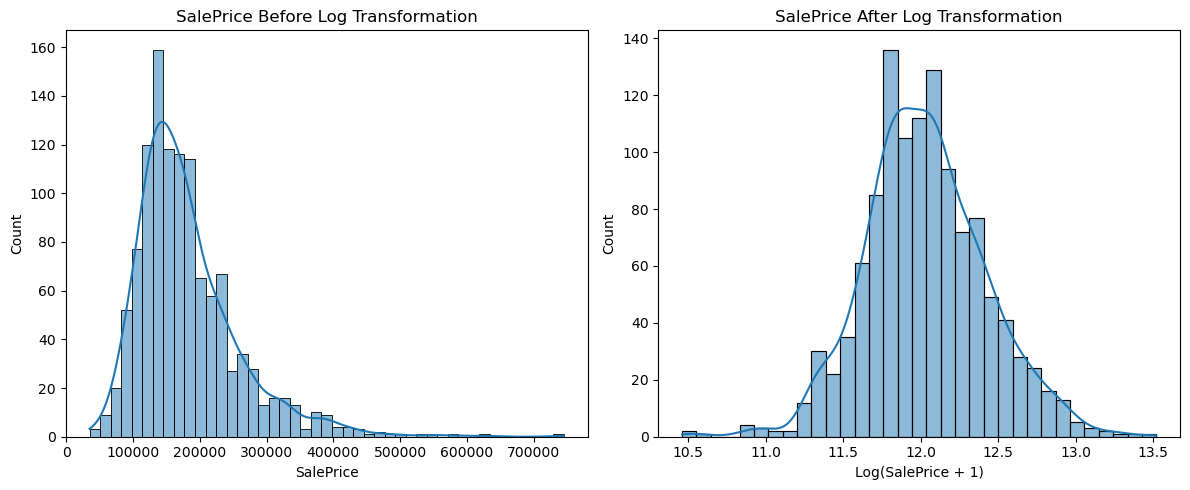

In [101]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 5))

# Before transformation
plt.subplot(1, 2, 1)
sns.histplot(y_train, kde=True)
plt.title("SalePrice Before Log Transformation")
plt.xlabel("SalePrice")
plt.ylabel("Count")

# After transformation
plt.subplot(1, 2, 2)
sns.histplot(y_train_log, kde=True)
plt.title("SalePrice After Log Transformation")
plt.xlabel("Log(SalePrice + 1)")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

### Observation

- The `SalePrice` distribution before transformation is **positively skewed**, with a skewness of **1.7431**.
- A `log1p` transformation was applied to the target variable `SalePrice` to reduce its right skewness.
- After transformation, the skewness decreased substantially from **1.7431 to 0.1249**.
- The histogram after transformation shows a distribution that is **much closer to symmetric/normal** compared with the original distribution.
- Therefore, the log transformation effectively reduced the skewness of the target variable and made `SalePrice` more suitable for regression modeling.
- The transformed target `y_train_log` was used for models where target transformation was beneficial.

In [102]:
X_train[numerical_cols].describe().T[["min", "max"]]

,min,max
MSSubClass,20.0,190.0
LotFrontage,21.0,313.0
LotArea,1300.0,215245.0
OverallQual,1.0,10.0
OverallCond,1.0,9.0
YearBuilt,1872.0,2010.0
YearRemodAdd,1950.0,2010.0
MasVnrArea,0.0,1378.0
BsmtFinSF1,0.0,5644.0
BsmtFinSF2,0.0,1127.0


## Scaling

In [103]:
from sklearn.preprocessing import StandardScaler

scaler_lr = StandardScaler()

X_train_scaled = scaler_lr.fit_transform(X_train_final)
X_test_scaled = scaler_lr.transform(X_test_final)

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled :", X_test_scaled.shape)

X_train_scaled: (1168, 257)
X_test_scaled : (292, 257)


In [104]:
print("Train shape:", X_train_scaled.shape)
print("Test shape :", X_test_scaled.shape)
print("Target train:", y_train_log.shape)
print("Target test :", y_test.shape)

Train shape: (1168, 257)
Test shape : (292, 257)
Target train: (1168,)
Target test : (292,)


### Observation

- `StandardScaler` was applied to the final numerical and one-hot encoded feature matrix to standardize the features before model training.
- The scaler was **fitted only on `X_train_final`** and then used to transform both the training and test datasets, preventing data leakage from the test set.
- The feature dimensions remained unchanged after scaling: **257 features** in both training and test sets.
- The training set contains **1,168 observations**, while the test set contains **292 observations**.
- The target variables contain **1,168 training observations** and **292 test observations**, matching the corresponding feature datasets.
- The final training and test datasets are therefore correctly aligned and ready for model training.

In [105]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print("MAE :", mae)
    print("RMSE:", rmse)
    print("R²  :", r2)

In [106]:
y_train_log

254     11.884496
1066    12.089544
638     11.350418
799     12.072547
380     11.751950
          ...    
1095    12.080696
1130    11.813037
1294    11.652696
860     12.154521
1126    12.066816
Name: SalePrice, Length: 1168, dtype: float64

## Baseline Models

## Ridge Regression

In [107]:
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=10)

ridge.fit(X_train_scaled, y_train_log)

ridge_pred_log = ridge.predict(X_test_scaled)
ridge_pred = np.expm1(ridge_pred_log)

print("Ridge Regression trained successfully.")

Ridge Regression trained successfully.


In [108]:
print("Min log prediction:", ridge_pred_log.min())
print("Max log prediction:", ridge_pred_log.max())
print("Infinite predictions:", np.isinf(ridge_pred).sum())

Min log prediction: 10.727974899192468
Max log prediction: 13.545214050018986
Infinite predictions: 0


In [ ]:
regression_metrics(y_test, ridge_pred)

MAE : 15847.331593992853
RMSE: 25158.401539116374
R²  : 0.9174813233614053


### Observation

- The baseline Ridge Regression model achieved an **MAE of 15,847.33**, indicating that the model's average absolute prediction error is approximately ₹15.85K.
- The model achieved an **RMSE of 25,158.40**, showing that larger prediction errors have a noticeable impact on the overall error.
- The **R² score of 0.91748** indicates that the model explains approximately **91.75% of the variation in house prices** in the test set.
- The baseline Ridge model provides a strong starting point for comparing the performance of subsequent models and experiments.

## Lasso Regression

In [110]:
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.01, max_iter=10000)

lasso.fit(X_train_scaled, y_train_log)

lasso_pred_log = lasso.predict(X_test_scaled)
lasso_pred = np.expm1(lasso_pred_log)

print("Lasso Regression trained successfully.")

Lasso Regression trained successfully.


In [111]:
regression_metrics(y_test, lasso_pred)

MAE : 17573.417828449175
RMSE: 28473.80997177885
R²  : 0.8942994297231728


### Observation

- The Lasso Regression model achieved an **MAE of 17,573.42**, indicating an average absolute prediction error of approximately ₹17.57K.
- The model achieved an **RMSE of 28,473.81**, which indicates that larger prediction errors have a noticeable impact on the overall error.
- The **R² score of 0.89430** indicates that the model explains approximately **89.43% of the variation in house prices** in the test set.
- Compared with the baseline Ridge Regression model, Lasso shows **higher MAE and RMSE and a lower R² score**, indicating weaker predictive performance on the test set.
- Therefore, based on these metrics, **Ridge Regression performs better than Lasso Regression** for this dataset.

## Decision Tree

In [112]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(
    random_state=42
)

dt.fit(X_train_final, y_train_log)

dt_pred_log = dt.predict(X_test_final)
dt_pred = np.expm1(dt_pred_log)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [113]:
regression_metrics(y_test, dt_pred)

MAE : 25809.534246575335
RMSE: 36816.69711929592
R²  : 0.8232840233699719


### Observation

- The Decision Tree Regression model achieved an **MAE of 25,809.53**, indicating an average absolute prediction error of approximately 25.81K.
- The model achieved an **RMSE of 36,816.70**, showing that the model makes relatively large prediction errors on some observations.
- The **R² score of 0.82328** indicates that the model explains approximately **82.33% of the variation in house prices** in the test set.
- Compared with the baseline Ridge Regression model, Decision Tree has **higher MAE and RMSE and a lower R² score**.
- Therefore, **Decision Tree Regression performs considerably worse than Ridge Regression** for this dataset.

## Random Forest

In [114]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_final, y_train_log)

rf_pred_log = rf.predict(X_test_final)
rf_pred = np.expm1(rf_pred_log)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [115]:
regression_metrics(y_test, rf_pred)

MAE : 17494.08162142687
RMSE: 29352.019690691686
R²  : 0.8876786936238141


### Observation

- The Random Forest Regression model achieved an **MAE of 17,494.08**, indicating an average absolute prediction error of approximately 17.49K.
- The model achieved an **RMSE of 29,352.02**, indicating that some larger prediction errors are affecting the overall performance.
- The **R² score of 0.88768** indicates that the model explains approximately **88.77% of the variation in house prices** in the test set.
- Compared with the baseline Ridge Regression model, Random Forest has **higher MAE and RMSE and a lower R² score**.
- Therefore, **Ridge Regression performs better than Random Forest Regression** for this dataset based on all three evaluation metrics.

## Gradient Boosting

In [116]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gbr.fit(X_train_final, y_train_log)

gbr_pred_log = gbr.predict(X_test_final)
gbr_pred = np.expm1(gbr_pred_log)

print("Gradient Boosting trained successfully.")

Gradient Boosting trained successfully.


In [117]:
regression_metrics(y_test, gbr_pred)

MAE : 16877.84439233495
RMSE: 30894.459006029298
R²  : 0.8755636238285557


### Observation

- The Gradient Boosting Regression model achieved an **MAE of 16,877.84**, indicating an average absolute prediction error of approximately 16.88K.
- The model achieved an **RMSE of 30,894.46**, indicating that larger prediction errors have a significant impact on the overall model performance.
- The **R² score of 0.87556** indicates that the model explains approximately **87.56% of the variation in house prices** in the test set.
- Compared with the baseline Ridge Regression model, Gradient Boosting has **higher MAE and RMSE and a lower R² score**.
- Therefore, **Ridge Regression performs better than Gradient Boosting Regression** for this dataset based on the current test-set results.

## XGBoost

In [118]:
import xgboost as xgb

print(xgb.__version__)

3.1.3


In [119]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_final, y_train_log)

xgb_pred_log = xgb_model.predict(X_test_final)
xgb_pred = np.expm1(xgb_pred_log)

print("XGBoost trained successfully.")

XGBoost trained successfully.


In [120]:
regression_metrics(y_test, xgb_pred)

MAE : 16170.990756100171
RMSE: 28285.240661496657
R²  : 0.8956947922706604


### Observation: Baseline XGBoost

- The baseline XGBoost model achieved an **MAE of 16,170.99**, **RMSE of 28,285.24**, and an **R² score of 0.89569**.
- The model explains approximately **89.57% of the variation in SalePrice**.
- Compared with the baseline Ridge model, XGBoost shows **higher MAE and RMSE and a lower R² score**.
- Therefore, **baseline Ridge performs better than baseline XGBoost** on the current test set.
- XGBoost will be further evaluated through **hyperparameter tuning** to check whether its performance can be improved.

## Model Comparison Based on R²

In [121]:
from sklearn.metrics import r2_score
import numpy as np

# -------------------------
# Ridge
# -------------------------
ridge_train_pred_log = ridge.predict(X_train_scaled)
ridge_train_pred = np.expm1(ridge_train_pred_log)

ridge_train_r2 = r2_score(y_train, ridge_train_pred)
ridge_test_r2 = r2_score(y_test, ridge_pred)


# -------------------------
# Lasso
# -------------------------
lasso_train_pred_log = lasso.predict(X_train_scaled)
lasso_train_pred = np.expm1(lasso_train_pred_log)

lasso_train_r2 = r2_score(y_train, lasso_train_pred)
lasso_test_r2 = r2_score(y_test, lasso_pred)


# -------------------------
# Decision Tree
# -------------------------
dt_train_pred_log = dt.predict(X_train_final)
dt_train_pred = np.expm1(dt_train_pred_log)

dt_train_r2 = r2_score(y_train, dt_train_pred)
dt_test_r2 = r2_score(y_test, dt_pred)


# -------------------------
# Random Forest
# -------------------------
rf_train_pred_log = rf.predict(X_train_final)
rf_train_pred = np.expm1(rf_train_pred_log)

rf_train_r2 = r2_score(y_train, rf_train_pred)
rf_test_r2 = r2_score(y_test, rf_pred)


# -------------------------
# Gradient Boosting
# -------------------------
gbr_train_pred_log = gbr.predict(X_train_final)
gbr_train_pred = np.expm1(gbr_train_pred_log)

gbr_train_r2 = r2_score(y_train, gbr_train_pred)
gbr_test_r2 = r2_score(y_test, gbr_pred)


# -------------------------
# XGBoost
# -------------------------
xgb_train_pred_log = xgb_model.predict(X_train_final)
xgb_train_pred = np.expm1(xgb_train_pred_log)

xgb_train_r2 = r2_score(y_train, xgb_train_pred)
xgb_test_r2 = r2_score(y_test, xgb_pred)

In [122]:
model_comparison = pd.DataFrame({
    "Model": [
        "Ridge",
        "Lasso",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],
    
    "Train R2": [
        ridge_train_r2,
        lasso_train_r2,
        dt_train_r2,
        rf_train_r2,
        gbr_train_r2,
        xgb_train_r2
    ],
    
    "Test R2": [
        ridge_test_r2,
        lasso_test_r2,
        dt_test_r2,
        rf_test_r2,
        gbr_test_r2,
        xgb_test_r2
    ]
})

model_comparison["R2_Score Gap"] = (
    model_comparison["Train R2"] -
    model_comparison["Test R2"]
)

model_comparison.sort_values(
    "Test R2",
    ascending=False
)

,Model,Train R2,Test R2,R2_Score Gap
0,Ridge,0.945153,0.917481,0.027671
5,XGBoost,0.969735,0.895695,0.074040
1,Lasso,0.871132,0.894299,-0.023167
3,Random Forest,0.977564,0.887679,0.089885
4,Gradient Boosting,0.973867,0.875564,0.098303
2,Decision Tree,1.000000,0.823284,0.176716


### Observation

- Ridge Regression achieved the **highest test R² of 0.91748** with a relatively small **R² gap of 0.02767**, indicating strong predictive performance and comparatively good generalization.
- XGBoost achieved a high **training R² of 0.96974**, but its test R² dropped to **0.89570**, resulting in a larger gap of **0.07404**, suggesting some degree of overfitting.
- Lasso showed a **negative R² gap (-0.02317)** because its test R² (0.89430) is slightly higher than its training R² (0.87113), indicating no evident overfitting based on this measure.
- Random Forest and Gradient Boosting show relatively large R² gaps of **0.08989** and **0.09830**, respectively, suggesting greater overfitting compared with Ridge.
- Decision Tree has the **largest R² gap of 0.17672**, with a perfect training R² of 1.00000 but a much lower test R² of 0.82328, indicating substantial overfitting.
- Overall, **Ridge Regression provides the best balance between training performance, test performance, and generalization before hyperparameter tuning**.

## Hyperparameter Tuning for Ridge Regression

In [123]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.compose import TransformedTargetRegressor


In [124]:
ridge_tuning = TransformedTargetRegressor(
    regressor=Ridge(),
    func=np.log1p,
    inverse_func=np.expm1
)


In [125]:
param_grid = {
    'regressor__alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

In [126]:
ridge_grid = GridSearchCV(
    estimator=ridge_tuning,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

ridge_grid.fit(X_train_scaled, y_train)

GridSearchCV(cv=5,
             estimator=TransformedTargetRegressor(func=<ufunc 'log1p'>,
                                                  inverse_func=<ufunc 'expm1'>,
                                                  regressor=Ridge()),
             n_jobs=-1,
             param_grid={'regressor__alpha': [0.001, 0.01, 0.1, 1, 10, 100,
                                              1000]},
             scoring='neg_mean_squared_error')

In [127]:
print("Best CV Score:", ridge_grid.best_score_)

Best CV Score: -1368330302.1032782


In [128]:
ridge_tuned_pred = ridge_grid.predict(X_test_scaled)

regression_metrics(y_test, ridge_tuned_pred)

MAE : 15523.964050355084
RMSE: 25455.045836441474
R²  : 0.9155238850300531


In [129]:
print("Best Parameters:", ridge_grid.best_params_)
print("Best CV RMSE:", np.sqrt(-ridge_grid.best_score_))

Best Parameters: {'regressor__alpha': 0.001}
Best CV RMSE: 36990.9489213683


In [130]:
cv_results = pd.DataFrame(ridge_grid.cv_results_)

print(cv_results.columns.tolist())

['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time', 'param_regressor__alpha', 'params', 'split0_test_score', 'split1_test_score', 'split2_test_score', 'split3_test_score', 'split4_test_score', 'mean_test_score', 'std_test_score', 'rank_test_score']


In [131]:
print(ridge_grid.estimator)
print(ridge_grid.param_grid)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Ridge())
{'regressor__alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]}


### Observation: Ridge Hyperparameter Tuning

- Hyperparameter tuning reduced the MAE from **15,847.33** to **15,523.96**, indicating a small improvement in average absolute error.
- However, RMSE increased from **25,158.40** to **25,455.04**, while R² decreased from **0.91748** to **0.91552**.
- Since RMSE and R² are the primary metrics considered for overall model performance, the tuned Ridge model does not provide an overall improvement over the baseline Ridge model.
- Therefore, the **baseline Ridge model is retained** for further comparison.

## Pipeline

In [132]:
categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

In [133]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.compose import TransformedTargetRegressor
import numpy as np

ridge_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numerical_cols
        ),
        (
            "cat",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        )
    ]
)

In [134]:
ridge_pipeline = Pipeline([
    ("preprocessor", ridge_preprocessor),
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10))
])

In [135]:
ridge_final = TransformedTargetRegressor(
    regressor=ridge_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

In [136]:
from copy import deepcopy

preprocessor_gbr = deepcopy(ridge_preprocessor)

In [137]:
ridge_final.fit(X_train, y_train)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('num',
                                                                                       'passthrough',
                                                                                       ['MSSubClass',
                                                                                        'LotFrontage',
                                                                                        'LotArea',
                                                                                        'OverallQual',
                                                                                        'OverallCond',
                                                                                        'YearBuilt',
                                                                                        'YearRemodAdd',
                                                                                        'MasVnrArea',
                                                                                        'BsmtFinSF1',
                                                                                        'BsmtFinSF2',
                                                                                        'BsmtUnfSF',
                                                                                        'TotalBsmtSF',
                                                                                        '1stFlrSF',
                                                                                        '2ndFlrSF',...
                                                                                        'LandSlope',
                                                                                        'Neighborhood',
                                                                                        'Condition1',
                                                                                        'Condition2',
                                                                                        'BldgType',
                                                                                        'HouseStyle',
                                                                                        'RoofStyle',
                                                                                        'RoofMatl',
                                                                                        'Exterior1st',
                                                                                        'Exterior2nd',
                                                                                        'MasVnrType',
                                                                                        'ExterQual',
                                                                                        'ExterCond',
                                                                                        'Foundation',
                                                                                        'BsmtQual',
                                                                                        'BsmtCond',
                                                                                        'BsmtExposure',
                                                                                        'BsmtFinType1',
                                                                                        'BsmtFinType2',
                                                                                        'Heating',
                                                                                        'HeatingQC',
                                                                                        'Ce

In [138]:
ridge_test_pred = ridge_final.predict(X_test)

In [139]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, ridge_test_pred)
rmse = np.sqrt(mean_squared_error(y_test, ridge_test_pred))
r2 = r2_score(y_test,ridge_test_pred )

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 15847.331593992853
RMSE: 25158.401539116374
R²  : 0.9174813233614053


### Observation: XGBoost — Baseline vs Pipeline

- The baseline XGBoost model achieved an **MAE of ₹16,170.99**, **RMSE of ₹28,285.24**, and an **R² score of 0.89569**.
- After integrating the preprocessing steps into a pipeline, XGBoost achieved the **same test-set performance**: **MAE of ₹16,170.99**, **RMSE of ₹28,285.24**, and an **R² score of 0.89569**.
- Therefore, converting the XGBoost workflow into a pipeline did **not change the model's predictive performance**.
- The pipeline is nevertheless retained because it provides a cleaner and more reliable workflow by combining preprocessing and model training into a single object.
- Hyperparameter tuning will be used to determine whether the XGBoost model's predictive performance can be improved.

## Residual Analysis

In [140]:
y_pred = ridge_final.predict(X_test)

In [141]:
residuals = y_test - y_pred

In [ ]:
print(residuals.head())

In [143]:
print(residuals.describe())

count       292.000000
mean       1130.278294
std       25176.145816
min     -103739.160049
25%       -9406.904153
50%         660.396558
75%        9943.519091
max      164888.041203
Name: SalePrice, dtype: float64


### Observation
Residual analysis was performed to identify systematic prediction errors. The residual distribution was examined to determine whether the model showed substantial bias or patterns that could indicate model inadequacy."

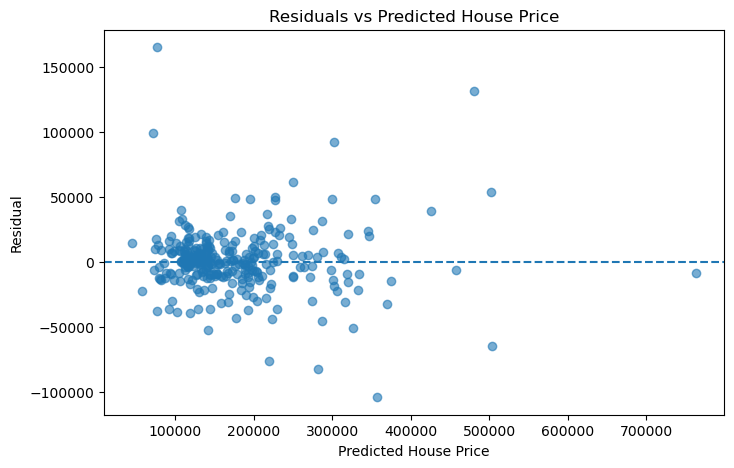

In [144]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.6)

plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted House Price")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted House Price")

plt.show()

### Observation

- The residuals are mostly scattered around the **zero reference line**, indicating that the Ridge model does not show a strong systematic bias across most predictions.
- Most observations are concentrated in the lower-to-middle predicted price range, with relatively small residuals around zero.
- However, several observations have **large positive and negative residuals**, indicating that the model makes substantial prediction errors for some houses.
- The presence of large residuals on both sides of zero suggests that the model **both underpredicts and overpredicts** certain house prices rather than consistently making errors in one direction.
- The spread of residuals appears to increase for some higher predicted-price observations, suggesting that the model may have **greater difficulty predicting certain higher-priced houses**.
- Therefore, residual analysis indicates that the Ridge model performs well overall but still has **a few influential large errors that contribute to the RMSE**.

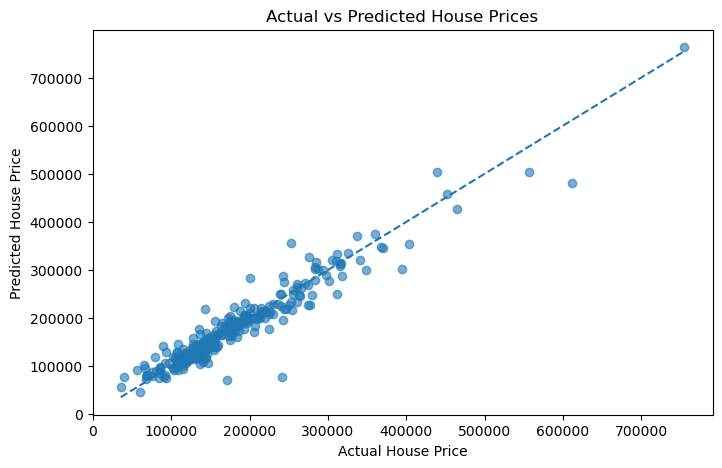

In [145]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

### Observation

- The points are generally concentrated around the **45-degree reference line**, indicating a strong agreement between actual and predicted house prices.
- The model performs particularly well for the **majority of houses in the lower-to-middle price range**, where the points are relatively close to the reference line.
- Some observations deviate noticeably from the reference line, indicating **larger prediction errors for a few houses**.
- The deviations become more noticeable for some **higher-priced houses**, suggesting that the model has greater difficulty accurately predicting certain expensive properties.
- Overall, the plot indicates that the Ridge Regression model has **strong predictive performance**, while a small number of observations contribute to the remaining prediction errors.

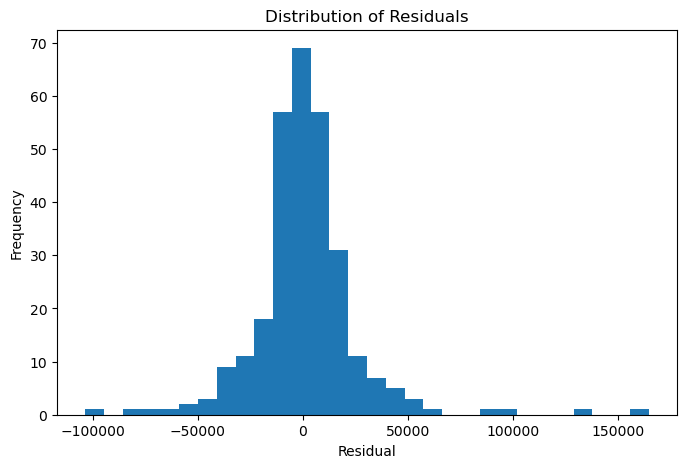

In [146]:
plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=30)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")

plt.show()

### Observation

- The residuals are **strongly concentrated around zero**, indicating that most predictions have relatively small errors.
- The distribution is approximately centered around zero, suggesting that the model does not show a strong overall bias toward consistently overpredicting or underpredicting house prices.
- Most residuals fall within a relatively narrow range around zero, while a few observations have **very large positive or negative residuals**.
- These extreme residuals indicate the presence of a small number of predictions with substantial errors, which contribute to the model's RMSE.
- Overall, the residual distribution suggests that the Ridge Regression model performs well for most observations but still has **some large prediction errors that require further investigation**.

## Experimenting for Performance Improvement

### Experiment: Effect of Log Transformation on Target Variable

- The effect of applying a **log transformation to the `SalePrice` target variable** is being evaluated to determine whether it improves the regression model's performance.
- Model performance with the log-transformed target will be compared with the corresponding model using the **original `SalePrice` scale**.
- The comparison will be based on **MAE, RMSE, and R²** on the test set.
- The log transformation will be retained only if it provides a meaningful improvement in the prediction performance.
- If the transformation does not improve the evaluation metrics, the original target scale will be preferred.

In [147]:
ridge_original_target = ridge_pipeline

In [148]:
ridge_original_target.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['MSSubClass', 'LotFrontage',
                                                   'LotArea', 'OverallQual',
                                                   'OverallCond', 'YearBuilt',
                                                   'YearRemodAdd', 'MasVnrArea',
                                                   'BsmtFinSF1', 'BsmtFinSF2',
                                                   'BsmtUnfSF', 'TotalBsmtSF',
                                                   '1stFlrSF', '2ndFlrSF',
                                                   'LowQualFinSF', 'GrLivArea',
                                                   'BsmtFullBath',
                                                   'BsmtHalfBath', 'FullBath',
                                                   'HalfBath', 'Bedro...
                                                   'LotConfig', 'LandSlope',
                                                   'Neighborhood', 'Condition1',
                                                   'Condition2', 'BldgType',
                                                   'HouseStyle', 'RoofStyle',
                                                   'RoofMatl', 'Exterior1st',
                                                   'Exterior2nd', 'MasVnrType',
                                                   'ExterQual', 'ExterCond',
                                                   'Foundation', 'BsmtQual',
                                                   'BsmtCond', 'BsmtExposure',
                                                   'BsmtFinType1',
                                                   'BsmtFinType2', 'Heating',
                                                   'HeatingQC', 'CentralAir',
                                                   'Electrical', ...])])),
                ('scaler', StandardScaler()), ('ridge', Ridge(alpha=10))])

In [149]:
y_pred_ridge_original = ridge_original_target.predict(X_test)

In [150]:
mae_original = mean_absolute_error(
    y_test,
    y_pred_ridge_original
)

rmse_original = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_ridge_original
    )
)

r2_original = r2_score(
    y_test,
    y_pred_ridge_original
)

print("MAE :", mae_original)
print("RMSE:", rmse_original)
print("R²  :", r2_original)

MAE : 19602.923948458487
RMSE: 34375.18902085577
R²  : 0.8459448023067977


### Observation: Effect of Log Transformation on Target Variable

- The Ridge model with the **log-transformed target** achieved an **MAE of 15,847.33**, **RMSE of 25,158.40**, and an **R² score of 0.91748**.
- When the model was trained using the **original `SalePrice` target**, it achieved an **MAE of 19,602.92**, **RMSE of 34,375.19**, and an **R² score of 0.84594**.
- The log-transformed target therefore produced **lower MAE and RMSE and a higher R²** compared with the original target.
- This indicates that the log transformation improved the Ridge model's predictive performance.
- Therefore, the **log-transformed target is retained** for the subsequent Ridge modeling experiments.

### XGBoost

In [151]:
from copy import deepcopy

xgb_preprocessor = deepcopy(ridge_preprocessor)

In [152]:
xgb_pipeline = Pipeline([
    ("preprocessor", xgb_preprocessor),
    ("xgb", xgb_model)
])

In [153]:
xgb_final = TransformedTargetRegressor(
    regressor=xgb_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

In [154]:
xgb_final.fit(X_train, y_train)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('num',
                                                                                       'passthrough',
                                                                                       ['MSSubClass',
                                                                                        'LotFrontage',
                                                                                        'LotArea',
                                                                                        'OverallQual',
                                                                                        'OverallCond',
                                                                                        'YearBuilt',
                                                                                        'YearRemodAdd',
                                                                                        'MasVnrArea',
                                                                                        'BsmtFinSF1',
                                                                                        'BsmtFinSF2',
                                                                                        'BsmtUnfSF',
                                                                                        'TotalBsmtSF',
                                                                                        '1stFlrSF',
                                                                                        '2ndFlrSF',...
                                                                   feature_weights=None,
                                                                   gamma=None,
                                                                   grow_policy=None,
                                                                   importance_type=None,
                                                                   interaction_constraints=None,
                                                                   learning_rate=0.05,
                                                                   max_bin=None,
                                                                   max_cat_threshold=None,
                                                                   max_cat_to_onehot=None,
                                                                   max_delta_step=None,
                                                                   max_depth=3,
                                                                   max_leaves=None,
                                                                   min_child_weight=None,
                                                                   missing=nan,
                                                                   monotone_constraints=None,
                                                                   multi_strategy=None,
                                                                   n_estimators=300,
                                                                   n_jobs=-1,
                                                                   num_parallel_tree=None, ...))]))

In [155]:
y_pred_xgb = xgb_final.predict(X_test)

In [156]:
mae_xgb = mean_absolute_error(
    y_test,
    y_pred_xgb
)

rmse_xgb = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_xgb
    )
)

r2_xgb = r2_score(
    y_test,
    y_pred_xgb
)

print("MAE :", mae_xgb)
print("RMSE:", rmse_xgb)
print("R²  :", r2_xgb)

MAE : 16170.990756100171
RMSE: 28285.240661496657
R²  : 0.8956947922706604


### Observation

- After validating the XGBoost model through the pipeline, the model achieved an **MAE of 16,170.99**, **RMSE of 28,285.24**, and an **R² score of 0.8956** on the test set.
- These results provide the **baseline performance for XGBoost after pipeline implementation**.
- Since XGBoost showed promising performance but did not outperform the Ridge model on RMSE and R², **hyperparameter tuning was performed to determine whether its performance could be further improved**.
- The tuned XGBoost model will be compared against these baseline metrics to determine whether hyperparameter tuning provides a meaningful improvement.

## Hyperparameter tuning for XGBoost

In [157]:
from sklearn.model_selection import RandomizedSearchCV

In [158]:
param_grid_xgb = {
    "regressor__xgb__n_estimators": [300, 500, 700],
    "regressor__xgb__learning_rate": [0.03, 0.05, 0.1],
    "regressor__xgb__max_depth": [2, 3, 4],
    "regressor__xgb__min_child_weight": [1, 3, 5],
    "regressor__xgb__subsample": [0.8, 1.0],
    "regressor__xgb__colsample_bytree": [0.8, 1.0]
}

In [159]:
xgb_random = RandomizedSearchCV(
    estimator=xgb_final,
    param_distributions=param_grid_xgb,
    n_iter=30,
    cv=5,
    scoring="neg_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [160]:
xgb_random.fit(X_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


RandomizedSearchCV(cv=5,
                   estimator=TransformedTargetRegressor(func=<ufunc 'log1p'>,
                                                        inverse_func=<ufunc 'expm1'>,
                                                        regressor=Pipeline(steps=[('preprocessor',
                                                                                   ColumnTransformer(transformers=[('num',
                                                                                                                    'passthrough',
                                                                                                                    ['MSSubClass',
                                                                                                                     'LotFrontage',
                                                                                                                     'LotArea',
                                                                                                                     'OverallQual',
                                                                                                                     'OverallCond',
                                                                                                                     'YearBuilt',
                                                                                                                     'YearRemodAdd',
                                                                                                                     'MasVnrArea',
                                                                                                                     'BsmtFinSF1',
                                                                                                                     'BsmtFinSF2',
                                                                                                                     'BsmtUnfSF',
                                                                                                                     'T...
                   n_iter=30, n_jobs=-1,
                   param_distributions={'regressor__xgb__colsample_bytree': [0.8,
                                                                             1.0],
                                        'regressor__xgb__learning_rate': [0.03,
                                                                          0.05,
                                                                          0.1],
                                        'regressor__xgb__max_depth': [2, 3, 4],
                                        'regressor__xgb__min_child_weight': [1,
                                                                             3,
                                                                             5],
                                        'regressor__xgb__n_estimators': [300,
                                                                         500,
                                                                         700],
                                        'regressor__xgb__subsample': [0.8,
                                                                      1.0]},
                   random_state=42, scoring='neg_mean_squared_error',
                   verbose=1)

In [161]:
best_xgb = xgb_random.best_estimator_

print("Best Parameters:")
print(xgb_random.best_params_)

Best Parameters:
{'regressor__xgb__subsample': 0.8, 'regressor__xgb__n_estimators': 700, 'regressor__xgb__min_child_weight': 3, 'regressor__xgb__max_depth': 3, 'regressor__xgb__learning_rate': 0.05, 'regressor__xgb__colsample_bytree': 0.8}


In [162]:
y_pred_xgb_tuned = best_xgb.predict(X_test)

mae_xgb_tuned = mean_absolute_error(
    y_test,
    y_pred_xgb_tuned
)

rmse_xgb_tuned = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_xgb_tuned
    )
)

r2_xgb_tuned = r2_score(
    y_test,
    y_pred_xgb_tuned
)

print("MAE :", mae_xgb_tuned)
print("RMSE:", rmse_xgb_tuned)
print("R²  :", r2_xgb_tuned)

MAE : 15342.738401648116
RMSE: 26044.249274774385
R²  : 0.9115679264068604


### Observation

- After hyperparameter tuning, the XGBoost model achieved an **MAE of 15,342.74**, **RMSE of 26,044.25**, and an **R² score of 0.91157**.
- Compared with the XGBoost model before tuning (**MAE = 16,170.99, RMSE = 28,285.24, R² = 0.89569**), the tuned model shows improvement across all three evaluation metrics.
- MAE decreased, RMSE decreased, and R² increased after hyperparameter tuning.
- Therefore, hyperparameter tuning **improved XGBoost's predictive performance**.
- However, the tuned XGBoost model still does not outperform the feature-engineered Ridge champion, which achieved a lower RMSE and higher R².

### Experiment: Ridge + XGBoost Ensemble

- Ridge Regression and the tuned XGBoost model are being combined to form an **ensemble model**.
- The ensemble predictions will be evaluated using **MAE, RMSE, and R²**.
- The objective is to determine whether combining the predictions of Ridge and XGBoost can provide **better overall performance** than either individual model.
- The ensemble will be retained only if it shows a meaningful improvement in the evaluation metrics, particularly **lower RMSE and higher R²**.

In [163]:
from sklearn.model_selection import KFold, cross_val_predict

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

ridge_oof = cross_val_predict(
    ridge_final,
    X_train,
    y_train,
    cv=cv,
    method="predict",
    n_jobs=1
)

xgb_oof = cross_val_predict(
    best_xgb,
    X_train,
    y_train,
    cv=cv,
    method="predict",
    n_jobs=1
)

In [164]:
from sklearn.metrics import mean_squared_error
import numpy as np

weights = np.arange(0, 1.01, 0.05)

results = []

for ridge_weight in weights:

    xgb_weight = 1 - ridge_weight

    ensemble_oof = (
        ridge_weight * ridge_oof
        + xgb_weight * xgb_oof
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_train,
            ensemble_oof
        )
    )

    results.append(
        (ridge_weight, xgb_weight, rmse)
    )

best_ridge_weight, best_xgb_weight, best_cv_rmse = min(
    results,
    key=lambda x: x[2]
)

print("Best Ridge Weight :", best_ridge_weight)
print("Best XGBoost Weight:", best_xgb_weight)
print("Best CV RMSE      :", best_cv_rmse)

Best Ridge Weight : 0.0
Best XGBoost Weight: 1.0
Best CV RMSE      : 27520.057380038666


In [165]:
ensemble_pred = (
    best_ridge_weight * ridge_test_pred
    + best_xgb_weight * y_pred_xgb_tuned
)

In [166]:
regression_metrics(y_test, ensemble_pred)

MAE : 15342.738401648116
RMSE: 26044.249274774385
R²  : 0.9115679174568855


### Observation: Ridge + XGBoost Ensemble

- The ensemble model achieved an **MAE of 15,342.74**, **RMSE of 26,044.25**, and an **R² score of 0.91157** on the test set.
- The optimal cross-validation weights were **0.0 for Ridge and 1.0 for XGBoost**.
- This means the optimized ensemble effectively selected **XGBoost alone**, rather than combining predictions from Ridge and XGBoost.
- Therefore, the ensemble did **not provide an improvement over the tuned XGBoost model**; its metrics are identical to the tuned XGBoost results.
- Since Ridge had a higher R² and lower RMSE than the ensemble, **Ridge remains the stronger model based on overall performance**.
- The ensemble experiment can therefore be **rejected and removed from the final modeling pipeline**, while its conclusion can be retained in the experiment summary.

### Experiment: Gradient Boosting

- Gradient Boosting is being evaluated to determine whether it can **improve the current model performance**.
- The model will be evaluated using **MAE, RMSE, and R²** on the test set.
- The results will be compared with the current **Ridge Regression champion**.
- Gradient Boosting will be retained only if it provides a meaningful improvement, particularly through **lower RMSE and MAE or higher R²**.

In [167]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    random_state=42
)

In [168]:
from copy import deepcopy

preprocessor_gbr = deepcopy(ridge_preprocessor)

In [169]:
gb_pipeline = Pipeline([
    ("preprocessor", preprocessor_gbr),
    ("scaler", StandardScaler()),
    ("model", gb_model)
])

In [170]:
gb_final = TransformedTargetRegressor(
    regressor=gb_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

In [171]:
from sklearn.model_selection import RandomizedSearchCV

param_dist_gb = {
    "regressor__model__n_estimators": [100, 200, 300, 500],
    "regressor__model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "regressor__model__max_depth": [2, 3, 4],
    "regressor__model__min_samples_split": [2, 5, 10],
    "regressor__model__min_samples_leaf": [1, 2, 4],
    "regressor__model__subsample": [0.8, 1.0]
}

gb_random = RandomizedSearchCV(
    estimator=gb_final,
    param_distributions=param_dist_gb,
    n_iter=30,
    cv=5,
    scoring="neg_mean_squared_error",
    random_state=42,
    n_jobs=-1
)

In [172]:
gb_random.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=TransformedTargetRegressor(func=<ufunc 'log1p'>,
                                                        inverse_func=<ufunc 'expm1'>,
                                                        regressor=Pipeline(steps=[('preprocessor',
                                                                                   ColumnTransformer(transformers=[('num',
                                                                                                                    'passthrough',
                                                                                                                    ['MSSubClass',
                                                                                                                     'LotFrontage',
                                                                                                                     'LotArea',
                                                                                                                     'OverallQual',
                                                                                                                     'OverallCond',
                                                                                                                     'YearBuilt',
                                                                                                                     'YearRemodAdd',
                                                                                                                     'MasVnrArea',
                                                                                                                     'BsmtFinSF1',
                                                                                                                     'BsmtFinSF2',
                                                                                                                     'BsmtUnfSF',
                                                                                                                     'T...
                   n_iter=30, n_jobs=-1,
                   param_distributions={'regressor__model__learning_rate': [0.01,
                                                                            0.03,
                                                                            0.05,
                                                                            0.1],
                                        'regressor__model__max_depth': [2, 3,
                                                                        4],
                                        'regressor__model__min_samples_leaf': [1,
                                                                               2,
                                                                               4],
                                        'regressor__model__min_samples_split': [2,
                                                                                5,
                                                                                10],
                                        'regressor__model__n_estimators': [100,
                                                                           200,
                                                                           300,
                                                                           500],
                                        'regressor__model__subsample': [0.8,
                                                                        1.0]},
                   random_state=42, scoring='neg_mean_squared_error')

In [173]:
best_gb = gb_random.best_estimator_

y_pred_gb = best_gb.predict(X_test)

mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Best Parameters:", gb_random.best_params_)
print("MAE :", mae_gb)
print("RMSE:", rmse_gb)
print("R²  :", r2_gb)

Best Parameters: {'regressor__model__subsample': 0.8, 'regressor__model__n_estimators': 200, 'regressor__model__min_samples_split': 5, 'regressor__model__min_samples_leaf': 4, 'regressor__model__max_depth': 3, 'regressor__model__learning_rate': 0.1}
MAE : 16630.76201014183
RMSE: 27778.91352212718
R²  : 0.8993956690203392


### Observation

- After hyperparameter tuning, the Gradient Boosting model achieved an **MAE of 16,630.76**, **RMSE of 27,778.91**, and an **R² score of 0.89940** on the test set.
- The tuned model does **not outperform the Ridge champion**, which has a lower RMSE and higher R².
- Therefore, hyperparameter tuning did not make Gradient Boosting competitive with the current Ridge model.
- Based on the current results, **Gradient Boosting can be rejected as the final model** and does not need further tuning.

## Feature Engineering

GrLivArea represents above-ground living area, while OverallQual represents the overall material and finish quality. Their interaction captures the idea that the value of additional living space depends on the quality of the property.

In [174]:
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

In [175]:
X_train_fe["Qual_GrLivArea"] = (
    X_train_fe["OverallQual"] *
    X_train_fe["GrLivArea"]
)

X_test_fe["Qual_GrLivArea"] = (
    X_test_fe["OverallQual"] *
    X_test_fe["GrLivArea"]
)

In [176]:
from copy import deepcopy

preprocessor_fe = deepcopy(
    xgb_final.regressor.named_steps["preprocessor"]
)

In [177]:
preprocessor_fe.transformers[0] = (
    "num",
    "passthrough",
    list(preprocessor_fe.transformers[0][2]) + ["Qual_GrLivArea"]
)

In [178]:
ridge_fe_pipeline = Pipeline([
    ("preprocessor", preprocessor_fe),
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10))
])

In [179]:
ridge_fe = TransformedTargetRegressor(
    regressor=ridge_fe_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

In [180]:
ridge_fe.fit(X_train_fe, y_train)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('num',
                                                                                       'passthrough',
                                                                                       ['MSSubClass',
                                                                                        'LotFrontage',
                                                                                        'LotArea',
                                                                                        'OverallQual',
                                                                                        'OverallCond',
                                                                                        'YearBuilt',
                                                                                        'YearRemodAdd',
                                                                                        'MasVnrArea',
                                                                                        'BsmtFinSF1',
                                                                                        'BsmtFinSF2',
                                                                                        'BsmtUnfSF',
                                                                                        'TotalBsmtSF',
                                                                                        '1stFlrSF',
                                                                                        '2ndFlrSF',...
                                                                                        'LandSlope',
                                                                                        'Neighborhood',
                                                                                        'Condition1',
                                                                                        'Condition2',
                                                                                        'BldgType',
                                                                                        'HouseStyle',
                                                                                        'RoofStyle',
                                                                                        'RoofMatl',
                                                                                        'Exterior1st',
                                                                                        'Exterior2nd',
                                                                                        'MasVnrType',
                                                                                        'ExterQual',
                                                                                        'ExterCond',
                                                                                        'Foundation',
                                                                                        'BsmtQual',
                                                                                        'BsmtCond',
                                                                                        'BsmtExposure',
                                                                                        'BsmtFinType1',
                                                                                        'BsmtFinType2',
                                                                                        'Heating',
                                                                                        'HeatingQC',
                                                                                        'Ce

In [181]:
y_pred_ridge_fe = ridge_fe.predict(X_test_fe)

In [182]:
mae_fe = mean_absolute_error(y_test, y_pred_ridge_fe)

rmse_fe = np.sqrt(
    mean_squared_error(y_test, y_pred_ridge_fe)
)

r2_fe = r2_score(y_test, y_pred_ridge_fe)

print("MAE :", mae_fe)
print("RMSE:", rmse_fe)
print("R²  :", r2_fe)

MAE : 15844.601941716022
RMSE: 25056.705481048786
R²  : 0.9181470940602587


### Observation: Feature Engineering — OverallQual × GrLivArea

- An interaction feature, **`Qual_GrLivArea`**, was created by multiplying `OverallQual` and `GrLivArea` to capture their combined effect on house prices.
- The feature-engineered Ridge model achieved an **MAE of 15,844.60**, **RMSE of 25,056.71**, and an **R² score of 0.91815**.
- Compared with the baseline Ridge model (**MAE = 15,847.33, RMSE = 25,158.40, R² = 0.91748**), the feature-engineered model shows a **slight improvement**.
- MAE decreased by approximately **₹2.73**, RMSE decreased by approximately **₹101.70**, and R² increased by approximately **0.00067**.
- Although the improvement is small, all three metrics move in the desired direction: **lower MAE, lower RMSE, and higher R²**.
- Therefore, the `Qual_GrLivArea` interaction feature is **retained** in the final Ridge model.

In [183]:
X_train_fe2 = X_train_fe.copy()
X_test_fe2 = X_test_fe.copy()

X_train_fe2["TotalSF"] = (
    X_train_fe2["GrLivArea"]
    + X_train_fe2["TotalBsmtSF"]
)

X_test_fe2["TotalSF"] = (
    X_test_fe2["GrLivArea"]
    + X_test_fe2["TotalBsmtSF"]
)

In [184]:
from copy import deepcopy

preprocessor_fe2 = deepcopy(preprocessor_fe)

In [185]:
num_features_fe2 = list(
    preprocessor_fe2.transformers[0][2]
)

num_features_fe2.append("TotalSF")

preprocessor_fe2.transformers[0] = (
    "num",
    "passthrough",
    num_features_fe2
)

In [186]:
ridge_fe2_pipeline = Pipeline([
    ("preprocessor", preprocessor_fe2),
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10))
])

In [187]:
ridge_fe2 = TransformedTargetRegressor(
    regressor=ridge_fe2_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

In [188]:
ridge_fe2.fit(X_train_fe2, y_train)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('num',
                                                                                       'passthrough',
                                                                                       ['MSSubClass',
                                                                                        'LotFrontage',
                                                                                        'LotArea',
                                                                                        'OverallQual',
                                                                                        'OverallCond',
                                                                                        'YearBuilt',
                                                                                        'YearRemodAdd',
                                                                                        'MasVnrArea',
                                                                                        'BsmtFinSF1',
                                                                                        'BsmtFinSF2',
                                                                                        'BsmtUnfSF',
                                                                                        'TotalBsmtSF',
                                                                                        '1stFlrSF',
                                                                                        '2ndFlrSF',...
                                                                                        'LandSlope',
                                                                                        'Neighborhood',
                                                                                        'Condition1',
                                                                                        'Condition2',
                                                                                        'BldgType',
                                                                                        'HouseStyle',
                                                                                        'RoofStyle',
                                                                                        'RoofMatl',
                                                                                        'Exterior1st',
                                                                                        'Exterior2nd',
                                                                                        'MasVnrType',
                                                                                        'ExterQual',
                                                                                        'ExterCond',
                                                                                        'Foundation',
                                                                                        'BsmtQual',
                                                                                        'BsmtCond',
                                                                                        'BsmtExposure',
                                                                                        'BsmtFinType1',
                                                                                        'BsmtFinType2',
                                                                                        'Heating',
                                                                                        'HeatingQC',
                                                                                        'Ce

In [189]:
y_pred_ridge_fe2 = ridge_fe2.predict(X_test_fe2)

mae_fe2 = mean_absolute_error(y_test, y_pred_ridge_fe2)

rmse_fe2 = np.sqrt(
    mean_squared_error(y_test, y_pred_ridge_fe2)
)

r2_fe2 = r2_score(y_test, y_pred_ridge_fe2)

print("MAE :", mae_fe2)
print("RMSE:", rmse_fe2)
print("R²  :", r2_fe2)

MAE : 15844.506123287629
RMSE: 25074.16108041375
R²  : 0.918033009691631


### Observation: Feature Engineering  TotalSF

- A new feature, **`TotalSF`**, was created by combining `GrLivArea` and `TotalBsmtSF` to represent the **total above-ground living area and basement area** of the house.
- The feature-engineered Ridge model achieved an **MAE of ₹15,844.51**, **RMSE of ₹25,074.16**, and an **R² score of 0.91803**.
- Compared with the previous feature-engineered Ridge model using `Qual_GrLivArea` (**RMSE = 25,056.71, R² = 0.91815**), adding `TotalSF` resulted in a **slight deterioration in performance**.
- RMSE increased from **₹25,056.71 to ₹25,074.16**, while R² decreased from **0.91815 to 0.91803**.
- Therefore, `TotalSF` does **not provide an improvement** over the existing feature-engineered model and should **not be retained as an additional feature**.

## Final Champion Error Analysis

In [ ]:
champion_pred = y_pred_ridge_fe

champion_error_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": champion_pred
}, index=y_test.index)

champion_error_df["Residual"] = (
    champion_error_df["Actual"]
    - champion_error_df["Predicted"]
)

champion_error_df["Absolute_Error"] = (
    champion_error_df["Residual"].abs()
)

worst_errors = champion_error_df.sort_values(
    "Absolute_Error",
    ascending=False
)

worst_indices = worst_errors.head(15).index

worst_errors.head(15)

In [ ]:
important_cols = [
    "OverallQual",
    "OverallCond",
    "GrLivArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "GarageCars",
    "GarageArea",
    "YearBuilt",
    "YearRemodAdd",
    "FullBath",
    "TotRmsAbvGrd",
    "Fireplaces",
    "MasVnrArea"
]

worst_analysis = X_test.loc[
    worst_indices,
    important_cols
].copy()

worst_analysis["ActualPrice"] = (
    champion_error_df.loc[worst_indices, "Actual"]
)

worst_analysis["PredictedPrice"] = (
    champion_error_df.loc[worst_indices, "Predicted"]
)

worst_analysis["Residual"] = (
    champion_error_df.loc[worst_indices, "Residual"]
)

worst_analysis.sort_values(
    "ActualPrice",
    ascending=False
)

In [ ]:
champion_error_df["OverallQual"] = X_test.loc[
    champion_error_df.index, "OverallQual"
]

quality_error = champion_error_df.groupby(
    "OverallQual"
).agg(
    MAE=("Absolute_Error", "mean"),
    RMSE=("Residual", lambda x: np.sqrt(np.mean(x**2))),
    Mean_Residual=("Residual", "mean"),
    Count=("Residual", "count")
)

print(quality_error)

### Observation: Error Analysis by Overall Quality

- The model's prediction error varies across different `OverallQual` levels.
- Houses with **OverallQual = 9** have the highest error, with an **MAE of 40,112.67** and **RMSE of 57,478.61**. However, this group contains only **7 observations**, so the result should be interpreted cautiously.
- `OverallQual = 10` also shows relatively high error (**MAE = 31,291.71**, **RMSE = 34,963.80**) with only **5 observations**.
- Among the larger groups, `OverallQual = 8` has relatively high error (**MAE = 22,043.67**, **RMSE = 32,857.26**), indicating that the model has more difficulty predicting houses in this quality range.
- `OverallQual = 5` has the lowest MAE among the major groups (**11,652.31**) and also has the largest number of observations (**89**).
- The mean residual is positive for `OverallQual = 3` and `7`, indicating a tendency toward **underprediction**, while most other quality groups have negative mean residuals, indicating a tendency toward **overprediction**.
- Overall, the model's errors tend to be larger for **higher-quality houses**, particularly `OverallQual = 8–10`, although the highest-quality groups have small sample sizes.

In [ ]:
champion_error_df["GrLivArea"] = X_test.loc[
    champion_error_df.index, "GrLivArea"
]

champion_error_df["Area_Group"] = pd.qcut(
    champion_error_df["GrLivArea"],
    q=5,
    labels=[
        "Very Small",
        "Small",
        "Medium",
        "Large",
        "Very Large"
    ]
)

area_error = champion_error_df.groupby(
    "Area_Group",
    observed=True
).agg(
    MAE=("Absolute_Error", "mean"),
    RMSE=("Residual", lambda x: np.sqrt(np.mean(x**2))),
    Mean_Residual=("Residual", "mean"),
    Count=("Residual", "count")
)

print(area_error)

### Observation: Error Analysis by Living Area

- The model's prediction error varies across different `GrLivArea` groups.
- The **Very Large** area group has the highest prediction error, with an **MAE of 26,997.68** and **RMSE of 37,994.53**.
- The **Medium** area group also has relatively high error, with an **MAE of 15,820.34** and **RMSE of 28,475.46**.
- The **Very Small** area group has the lowest MAE (**10,070.99**) and RMSE (**13,596.65**), indicating better prediction accuracy for smaller houses.
- The **Large** area group has relatively low error, with an **MAE of 12,195.85** and **RMSE of 16,432.65**.
- The mean residual is positive for the **Medium, Large, and Very Large** groups, indicating a tendency toward **underprediction** in these groups.
- Overall, the model has greater difficulty predicting houses with **very large living areas**, suggesting that extreme house sizes contribute more to prediction error.

## Weighted Ridge Regression


In [194]:
y_train_weights = y_train / y_train.median()

In [195]:
y_train_weights = np.clip(
    y_train_weights,
    0.5,
    3.0
)

In [196]:
ridge_fe.fit(
    X_train_fe,
    y_train,
    ridge__sample_weight=y_train_weights
)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('num',
                                                                                       'passthrough',
                                                                                       ['MSSubClass',
                                                                                        'LotFrontage',
                                                                                        'LotArea',
                                                                                        'OverallQual',
                                                                                        'OverallCond',
                                                                                        'YearBuilt',
                                                                                        'YearRemodAdd',
                                                                                        'MasVnrArea',
                                                                                        'BsmtFinSF1',
                                                                                        'BsmtFinSF2',
                                                                                        'BsmtUnfSF',
                                                                                        'TotalBsmtSF',
                                                                                        '1stFlrSF',
                                                                                        '2ndFlrSF',...
                                                                                        'LandSlope',
                                                                                        'Neighborhood',
                                                                                        'Condition1',
                                                                                        'Condition2',
                                                                                        'BldgType',
                                                                                        'HouseStyle',
                                                                                        'RoofStyle',
                                                                                        'RoofMatl',
                                                                                        'Exterior1st',
                                                                                        'Exterior2nd',
                                                                                        'MasVnrType',
                                                                                        'ExterQual',
                                                                                        'ExterCond',
                                                                                        'Foundation',
                                                                                        'BsmtQual',
                                                                                        'BsmtCond',
                                                                                        'BsmtExposure',
                                                                                        'BsmtFinType1',
                                                                                        'BsmtFinType2',
                                                                                        'Heating',
                                                                                        'HeatingQC',
                                                                                        'Ce

In [197]:
y_pred_weighted = ridge_fe.predict(X_test_fe)

In [198]:
mae_weighted = mean_absolute_error(
    y_test,
    y_pred_weighted
)

rmse_weighted = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_weighted
    )
)

r2_weighted = r2_score(
    y_test,
    y_pred_weighted
)

print("MAE :", mae_weighted)
print("RMSE:", rmse_weighted)
print("R²  :", r2_weighted)

MAE : 15806.540785052004
RMSE: 25225.10041260762
R²  : 0.9170432034259617


In [199]:
ridge_fe.fit(
    X_train_fe,
    y_train
)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('num',
                                                                                       'passthrough',
                                                                                       ['MSSubClass',
                                                                                        'LotFrontage',
                                                                                        'LotArea',
                                                                                        'OverallQual',
                                                                                        'OverallCond',
                                                                                        'YearBuilt',
                                                                                        'YearRemodAdd',
                                                                                        'MasVnrArea',
                                                                                        'BsmtFinSF1',
                                                                                        'BsmtFinSF2',
                                                                                        'BsmtUnfSF',
                                                                                        'TotalBsmtSF',
                                                                                        '1stFlrSF',
                                                                                        '2ndFlrSF',...
                                                                                        'LandSlope',
                                                                                        'Neighborhood',
                                                                                        'Condition1',
                                                                                        'Condition2',
                                                                                        'BldgType',
                                                                                        'HouseStyle',
                                                                                        'RoofStyle',
                                                                                        'RoofMatl',
                                                                                        'Exterior1st',
                                                                                        'Exterior2nd',
                                                                                        'MasVnrType',
                                                                                        'ExterQual',
                                                                                        'ExterCond',
                                                                                        'Foundation',
                                                                                        'BsmtQual',
                                                                                        'BsmtCond',
                                                                                        'BsmtExposure',
                                                                                        'BsmtFinType1',
                                                                                        'BsmtFinType2',
                                                                                        'Heating',
                                                                                        'HeatingQC',
                                                                                        'Ce

In [200]:
final_pred = ridge_fe.predict(X_test_fe)

In [201]:
print("MAE :", mean_absolute_error(y_test, final_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, final_pred)))
print("R²  :", r2_score(y_test, final_pred))

MAE : 15844.601941716022
RMSE: 25056.705481048786
R²  : 0.9181470940602587


### Weighted Ridge Regression

Weighted Ridge was tested to determine whether assigning greater weight to higher-priced houses could reduce large prediction errors. However, the approach increased RMSE and reduced R² compared with the feature-engineered Ridge model. Therefore, weighted Ridge was rejected.

## Overall Model Evaluation

Multiple regression models were developed and evaluated using MAE, RMSE, and R² on the test set.

The main models included Ridge Regression, Lasso Regression, Decision Tree, Random Forest, Gradient Boosting, and XGBoost. Hyperparameter tuning, pipeline implementation, ensemble modeling, and feature engineering were also performed to improve model performance.

The final comparison showed that the feature-engineered Ridge Regression model with the `Qual_GrLivArea` interaction feature achieved the best overall performance.

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Ridge + Qual_GrLivArea | 15,844.60 | 25,056.71 | 0.91815 |
| Tuned XGBoost | 15,342.74 | 26,044.25 | 0.91157 |
| Baseline Ridge | 15,847.33 | 25,158.40 | 0.91748 |
| Lasso | 17,573.42 | 28,473.81 | 0.89430 |
| Random Forest | 17,494.08 | 29,352.02 | 0.88768 |
| Gradient Boosting | 16,877.84 | 30,894.46 | 0.87556 |
| Decision Tree | 25,809.53 | 36,816.70 | 0.82328 |

Although XGBoost achieved competitive MAE, the final Ridge model provided a better balance of RMSE and R² while remaining simpler and more interpretable. Therefore, Ridge with Qual_GrLivArea was selected as the final model.

## Final Conclusion

This project developed an end-to-end machine learning solution for predicting house sale prices.

The workflow included data understanding, exploratory data analysis, missing-value treatment, categorical encoding, feature scaling, target transformation, baseline model development, hyperparameter tuning, pipeline implementation, feature engineering, ensemble experimentation, and detailed error analysis.

The final champion model was a Ridge Regression model with the `Qual_GrLivArea` interaction feature and log-transformed target.

The final model achieved:

- **MAE:** ₹15,844.60
- **RMSE:** ₹25,056.71
- **R²:** 0.91815

The model explains approximately **91.82% of the variation in SalePrice** in the test dataset .

Additional experiments with XGBoost, Gradient Boosting, ensemble modeling, `TotalSF`, and weighted Ridge did not provide an overall improvement over the final Ridge model.

Therefore, the **feature-engineered Ridge Regression model is selected as the final model for house price prediction**.

## Business Interpretation

The analysis provides several useful insights into the factors associated with house prices:

- **Overall quality of the property:** Overall quality is an important factor associated with house price. Higher-quality properties generally tend to have higher predicted prices.

- **Above-ground living area:** Larger above-ground living areas are generally associated with higher house prices. However, the effect of additional living area also depends on the overall quality of the property.

- **Quality × Living Area interaction:** The engineered feature `Qual_GrLivArea` captures the combined effect of property quality and living area. This helps the model represent that additional living space can have different value depending on the quality of the property.

- **Property characteristics:** Features related to the size, condition, quality, and facilities of a property contribute to differences in predicted prices.

- **Model performance:** The final model achieved an R² of approximately 0.918, indicating that the model explains a substantial proportion of the variation in house prices in the test dataset.

### Customer Recommendations

- Buyers should consider **overall property quality and usable living area** together rather than evaluating house size alone.
- Buyers with a limited budget can compare properties based on their combination of **quality, size, and available facilities**.
- Sellers can use the model as an initial reference for understanding how property characteristics are associated with market prices.
- Real-estate analysts can use such models to support **data-driven price estimation and property comparison**.

## Limitations

Although the final model provides strong predictive performance, there are several limitations:

- **Geographical limitation:** The dataset represents houses from Ames, Iowa. Therefore, the model may not generalize directly to housing markets in other cities or countries.

- **Historical data limitation:** The model learns patterns from the available historical data. Changes in economic conditions, interest rates, housing demand, and market conditions may affect future prices.

- **Feature limitation:** House prices can be influenced by factors that are not available in the dataset, such as current market demand, accessibility, nearby amenities, economic conditions, and buyer preferences.

- **Generalization:** A strong test-set performance does not guarantee the same level of performance on completely new datasets or different housing markets.

- **Prediction uncertainty:** The model provides an estimated price rather than a guaranteed market price. Individual properties may have prices that differ from the model's prediction because of factors not captured by the available features.

Therefore, the model should be treated as a **decision-support tool rather than a replacement for professional property valuation**.

## Challenges Faced

- Handling missing values across numerical and categorical features.
- Managing categorical variables through appropriate encoding.
- Dealing with the skewed `SalePrice` target variable.
- Identifying overfitting and selecting the best-performing model among multiple algorithms.

## Solutions Implemented

- Applied appropriate imputation techniques for missing values.
- Used One-Hot Encoding for categorical variables and StandardScaler for models requiring feature scaling.
- Applied log transformation to `SalePrice` to reduce skewness and improve model performance.
- Compared multiple models, performed hyperparameter tuning, and used feature engineering to select the final model.

## Future Scope

- Incorporate additional location and market-related features to improve predictions.
- Use cross-validation to obtain more robust estimates of model performance.
- Explore advanced ensemble and boosting techniques for further performance improvement.
- Apply model interpretability techniques such as SHAP or permutation importance to better understand feature contributions.
- Deploy the final model as a web application for real-world house price prediction.
- Monitor and retrain the model periodically using new housing market data.

## Save the Final Model

In [202]:
import joblib

joblib.dump(
    ridge_fe,
    "final_house_price_ridge_model.pkl"
)

print("Final model saved successfully.")

Final model saved successfully.


## Model Saving and Loading

The final champion Ridge model was saved using `joblib` so that the trained model can be reused without retraining it from scratch.

In [203]:
loaded_model = joblib.load(
    "final_house_price_ridge_model.pkl"
)

print("Final model loaded successfully.")

Final model loaded successfully.


## Load the Final Model

The saved model was successfully loaded and tested on the test data. The loaded model produced the same evaluation results as the original trained model, confirming that the model was saved and restored correctly.

## References

- Scikit-learn Documentation — Machine Learning algorithms, preprocessing, pipelines, model selection, and evaluation metrics.
- Pandas Documentation — Data manipulation and analysis.
- NumPy Documentation — Numerical computing and mathematical operations.
- Matplotlib Documentation — Data visualization.
- Seaborn Documentation — Statistical data visualization.
- Kaggle — House Prices: Advanced Regression Techniques dataset.

## Appendix

The appendix contains supporting code and outputs used during the project, including:

- Data preprocessing code
- Missing-value treatment
- Encoding and scaling
- Model training code
- Hyperparameter tuning code
- Feature engineering experiments
- Residual and error analysis
- Model comparison results
- Final model saving and loading code

## Thank You

Thank you for taking the time to review my project.

I sincerely appreciate your feedback and suggestions. I am always open to learning, improving my approach, and incorporating constructive feedback to make this project better.

**I am ready to receive your suggestions and recommendations.**